# Unit 4 group project: TrashNet class-imbalance experiments

Unit 3 showed that **spatially aware features** (the DINOv3 ConvNeXt-Tiny
feature map reduced to a 2x2 grid, 3,072 values) beat global pooled features,
and that the weakest classes were the minority **trash** class (95 of 1,768
training images, 5.4%) and **plastic**, which is confused with trash and glass.
This notebook keeps the best representation, uses the larger prediction head,
and targets the imbalance problem directly:

| Run | Loss | Optimizer | Purpose |
|---|---|---|---|
| `control_ce` | softmax cross entropy | Adam | same setup, Unit 3 loss: isolates the loss change |
| `exp1_focal` | alpha-balanced focal loss (gamma 2, inverse-frequency alpha) | Adam | Experiment 1 |
| `exp2_logit_adjusted` | logit-adjusted cross entropy (tau 1) + label smoothing 0.1 | AdamW (wd 0.05) | Experiment 2 |

Shared by every run: frozen backbone (both T4 GPUs for extraction), 2x2 spatial
features, larger head (40 GELU -> dropout 0.1 -> 24 GELU -> dropout 0.1 -> 6),
global batch 256 (128 per GPU via `MirroredStrategy`), WSD learning rate
(10% warmup / 70% stable / 20% decay to 1% of a 2e-3 peak), 100 epochs. Each
run saves its **best-validation-loss** head and its **last-epoch** head; both
are scored on train, validation, and the held-out test split.

All modeling uses TensorFlow / Keras.


## 1. Compatible dependencies

Kaggle's November 2026 GPU image ships TensorFlow 2.21, protobuf 7.36, Keras
3.13.2, and datasets 4.8.5. TensorFlow and protobuf are kept as shipped; Unit 3's
TF 2.20 / protobuf 5.29 downgrades now conflict with preinstalled Google Cloud
packages. Only these are changed:
- `keras==3.15.1`: the version that saved and validated the DINOv3 artifact.
- `datasets==5.1.0`: the version that produced the Unit 3 split. Its stratified
  split code matches 4.8.5, but its image-folder loader differs, so row order
  could differ.
- `Pillow==12.3.0`: the Unit 3 JPEG decoder version; it also satisfies Gradio's `pillow<13`.
- `google-cloud-bigquery-storage==2.43.0`: required by preinstalled BigFrames.
- `ydf==0.17.0`: the shipped 0.15 requires `protobuf<7`.
- Uninstalled, all unused: Dopamine, Google Colab, and legacy MoviePy (pin
  conflicts), plus RAPIDS `cudf-cu13`, `dask-cudf-cu13`, and `cuml-cu13`. cudf
  26.6 requires `pyarrow<24`, while datasets 5.1 requires `pyarrow>=24`.

`pip check` must pass before any import, so a dependency conflict fails setup
instead of being ignored. The environment was verified with a probe kernel.


In [1]:
# Install compatible pins before importing TensorFlow or dataset libraries.
import subprocess
import sys
import time

# Runtime covers setup, extraction, training, scoring, and plots (not queue time).
notebook_started = time.perf_counter()

# Unused preinstalled distributions whose requirements conflict (see markdown above).
subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y',
                'dopamine-rl', 'google-colab', 'moviepy',
                'cudf-cu13', 'dask-cudf-cu13', 'cuml-cu13'], check=True)
requirements = [
    'keras==3.15.1', 'datasets==5.1.0', 'Pillow==12.3.0',
    'google-cloud-bigquery-storage==2.43.0', 'ydf==0.17.0',
]
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet',
                '--disable-pip-version-check', *requirements], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'check'], check=True)

from importlib import metadata
print({name: metadata.version(name) for name in
       ('tensorflow', 'keras', 'protobuf', 'datasets', 'pyarrow', 'Pillow', 'kagglehub')})


Found existing installation: dopamine_rl 4.1.2
Uninstalling dopamine_rl-4.1.2:
  Successfully uninstalled dopamine_rl-4.1.2
Found existing installation: google-colab 1.0.0
Uninstalling google-colab-1.0.0:
  Successfully uninstalled google-colab-1.0.0
Found existing installation: moviepy 1.0.3
Uninstalling moviepy-1.0.3:
  Successfully uninstalled moviepy-1.0.3
Found existing installation: cudf-cu13 26.6.0
Uninstalling cudf-cu13-26.6.0:
  Successfully uninstalled cudf-cu13-26.6.0
Found existing installation: dask-cudf-cu13 26.6.0
Uninstalling dask-cudf-cu13-26.6.0:
  Successfully uninstalled dask-cudf-cu13-26.6.0
Found existing installation: cuml-cu13 26.6.0
Uninstalling cuml-cu13-26.6.0:
  Successfully uninstalled cuml-cu13-26.6.0
No broken requirements found.
{'tensorflow': '2.21.0', 'keras': '3.15.1', 'protobuf': '7.36.2', 'datasets': '5.1.0', 'pyarrow': '26.0.1', 'Pillow': '12.3.0', 'kagglehub': '1.0.3'}


## 2. Configuration and GPU check

In [2]:
import os
from pathlib import Path

# Select the backend before importing Keras, and reduce TensorFlow log noise.
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import numpy as np
import pandas as pd
import tensorflow as tf
# Memory growth must be configured before any GPU tensor or strategy exists.
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
import keras
import kagglehub
from datasets import ClassLabel, DatasetDict, Image, load_dataset
from IPython.display import display

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Visible GPUs:", tf.config.list_physical_devices('GPU'))

# Data and model inputs (attached to the Kaggle kernel).
DATASET_HANDLE = "feyzazkefe/trashnet"     # Kaggle TrashNet, 2,527 images at 512x384
DATASET_SUBDIR = "dataset-resized"         # one folder per class inside the dataset
MODEL_HANDLE = "mataeoanderson/dinov3-convnext/keras/tiny/1"
MODEL_FILENAME = "dinov3_convnext_tiny.keras"
SEED = 42
# Backbone inference batch per GPU; global batch = 8 x 2 GPUs = 16 images.
PER_REPLICA_EXTRACTION_BATCH = 8
keras.utils.set_random_seed(SEED)


TensorFlow: 2.21.0 | Keras: 3.15.1
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 3. Embedded helpers

The first cell is Unit 3's `baselines.py`, unchanged: the stratified splitter,
native-resolution preprocessing, the `WarmStableDecay` learning-rate schedule,
and `evaluate_probabilities`. The second cell is `unit4_helpers.py`: two-GPU
extraction, logit heads, the three losses, and reporting. `build_notebooks.py`
regenerates these cells from the source files.


In [3]:
"""Reusable TensorFlow heads, frozen-feature caching, and train/dev reporting.

The notebook embeds this module so Kaggle needs only Notebook.ipynb. No helper
accepts a test feature array: test evaluation belongs to a later final-model run.
"""
import json
import math
from pathlib import Path

import keras
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from datasets import DatasetDict


def split_dataset(published, seed=42, test_fraction=0.15, validation_fraction=0.15):
    """Honor DatasetDict author splits; stratify only missing partitions.

    Dataset.train_test_split returns DatasetDict with 'train' and 'test' keys.
    Its temporary 'test' partition becomes validation when splitting train/dev.
    Existing columns are preserved; row_id records original split membership.
    """
    splits = DatasetDict({name: data.add_column('row_id', [f'{name}:{i}' for i in range(len(data))])
                          for name, data in published.items()})
    if 'train' not in splits:
        raise ValueError('A published train split is required.')
    if 'validation' not in splits and 'dev' in splits:
        splits['validation'] = splits.pop('dev')
    if 'test' not in splits:
        partition = splits['train'].train_test_split(
            test_size=test_fraction, seed=seed, stratify_by_column='label')
        splits['train'], splits['test'] = partition['train'], partition['test']
        dev_fraction = validation_fraction / (1 - test_fraction)
    else:
        dev_fraction = validation_fraction
    if 'validation' not in splits:
        partition = splits['train'].train_test_split(
            test_size=dev_fraction, seed=seed, stratify_by_column='label')
        splits['train'], splits['validation'] = partition['train'], partition['test']
    ids = {name: set(splits[name]['row_id']) for name in ('train', 'validation', 'test')}
    assert not (ids['train'] & ids['validation'] or ids['train'] & ids['test'] or ids['validation'] & ids['test'])
    return splits


def preprocess_image(rgb_image):
    """Preserve every native RGB pixel; apply only scale and ImageNet normalization."""
    pixels = tf.convert_to_tensor(np.asarray(rgb_image.convert('RGB')), dtype=tf.float32) / 255.0
    mean = tf.constant([0.485, 0.456, 0.406], dtype=tf.float32)
    std = tf.constant([0.229, 0.224, 0.225], dtype=tf.float32)
    return ((pixels - mean) / std)[None, ...]


def prepare_pooled_backbone(backbone, mixed_precision=False):
    """Build a frozen pooled-only graph, preserving every pretrained weight.

    Eager Functional execution retains intermediate tensors until the call ends.
    At native multi-megapixel resolutions the expanded ConvNeXt activations can
    exhaust a T4 even with batch size one. Graph execution enables tensor-lifetime
    planning; pooled-only output also prunes the unused spatial-output branch.
    On GPU, mixed-float16 convolution/dense activations further halve their size.
    Normalization and global pooling stay float32; all variables stay float32.
    Heads and the shared RAM cache remain float32. No spatial pixels are changed.
    """
    if not isinstance(backbone.output, dict) or set(backbone.output) != {'pooled', 'feature_map'}:
        raise ValueError('Expected the Tiny backbone pooled/feature_map output contract.')
    pooled_model = keras.Model(backbone.inputs, backbone.output['pooled'], name='frozen_pooled_backbone')
    if mixed_precision:
        def clone_layer(layer):
            # Documented clone_function receives each non-Input layer instance.
            # Its config is copied explicitly; no checkpoint weights are modified.
            config = layer.get_config()
            config['dtype'] = 'float32' if isinstance(layer, (keras.layers.LayerNormalization, keras.layers.GlobalAveragePooling2D)) else 'mixed_float16'
            return layer.__class__.from_config(config)
        mixed_model = keras.models.clone_model(pooled_model, clone_function=clone_layer)
        mixed_model.set_weights(pooled_model.get_weights())
        pooled_model = mixed_model
    pooled_model.trainable = False
    assert not pooled_model.trainable_weights
    return pooled_model


def pooled_inference_function(pooled_model):
    """One dynamic-shape graph for all native image sizes, returning float32."""
    @tf.function(input_signature=[tf.TensorSpec((1, None, None, 3), tf.float32)])
    def infer(pixels):
        return tf.cast(pooled_model(pixels, training=False), tf.float32)
    return infer


def cache_pooled_features(backbone, splits):
    """One extraction pass, one inference per train/dev image, shared by all heads.

    The prepared frozen model returns only pooled (N,768), pruning spatial output.
    Single-image inference supports mixed native sizes without padding or resize.
    Dataset rows supply image, label, row_id; other columns are unused.
    """
    backbone.trainable = False
    assert not backbone.trainable_weights
    infer = pooled_inference_function(backbone)
    cache, shapes, calls = {}, {}, 0
    for name in ('train', 'validation'):
        data = splits[name]
        vectors = np.empty((len(data), 768), dtype=np.float32)
        labels = np.asarray(data['label'], dtype=np.int32)
        for i, row in enumerate(data):
            pixels = preprocess_image(row['image'])
            pooled = infer(pixels)
            assert tuple(pooled.shape) == (1, 768)
            tf.debugging.assert_all_finite(pooled, 'Non-finite pooled features')
            vectors[i] = pooled.numpy()[0]
            shape = str(tuple(pixels.shape[1:3]))
            shapes[shape] = shapes.get(shape, 0) + 1
            calls += 1
            if i == 0 or (i + 1) % 25 == 0 or i + 1 == len(data):
                print(f'{name}: cached {i + 1}/{len(data)}', flush=True)
        cache[name] = (vectors, labels)
    assert calls == len(splits['train']) + len(splits['validation'])
    print('Backbone inference calls:', calls, '| Native resolutions:', shapes)
    print('Feature cache MiB:', sum(x.nbytes + y.nbytes for x, y in cache.values()) / 2**20)
    return cache, {'inference_calls': calls, 'native_shapes': shapes, 'test_inference_calls': 0}


@keras.saving.register_keras_serializable(package='Unit3')
class WarmStableDecay(keras.optimizers.schedules.LearningRateSchedule):
    """Batch-based linear 10% warmup / 70% stable / 20% decay over 50 epochs.

    Early stopping may finish before decay; the schedule uses the planned budget,
    never the unknowable eventual stopping epoch. End learning rate is 1% of peak.
    """
    def __init__(self, total_steps, peak_lr=0.001):
        self.total_steps = int(total_steps)
        self.peak_lr = float(peak_lr)
        self.warmup = max(1, int(round(total_steps * 0.1)))
        self.decay_start = int(round(total_steps * 0.8))

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = self.peak_lr * (step + 1) / self.warmup
        progress = tf.clip_by_value((step - self.decay_start) / max(1, self.total_steps - self.decay_start - 1), 0., 1.)
        decay = self.peak_lr * (1. - 0.99 * progress)
        return tf.where(step < self.warmup, warm, tf.where(step < self.decay_start, self.peak_lr, decay))

    def get_config(self):
        return {'total_steps': self.total_steps, 'peak_lr': self.peak_lr}


def build_head(feature_dim, num_classes, hidden_units=(), name='linear', dropout_rates=()):
    """Dense softmax classifier for any fixed-width feature representation.

    A spatial experiment can supply vectors of another width or add its own
    spatial aggregation before this head. The default is multinomial logistic
    regression; hidden_units=(8,) adds one small GELU layer. Optional dropout
    rates apply after the corresponding hidden layers, only during training.
    """
    if len(dropout_rates) > len(hidden_units):
        raise ValueError('Dropout rates must correspond to existing hidden layers.')
    inputs = keras.Input(shape=(feature_dim,), name='features')
    x = inputs
    for i, units in enumerate(hidden_units):
        x = keras.layers.Dense(units, activation='gelu', name=f'hidden_{i}')(x)
        if i < len(dropout_rates):
            # Keras fit enables dropout; validation/predict keep every unit active.
            x = keras.layers.Dropout(dropout_rates[i], name=f'dropout_{i}')(x)
    probabilities = keras.layers.Dense(num_classes, activation='softmax', name='probabilities')(x)
    return keras.Model(inputs, probabilities, name=name)


def feature_dataset(x, y, batch_size, training=False, seed=42):
    """Batch RAM features with a bounded TF thread pool for portable execution."""
    data = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        data = data.shuffle(len(y), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return data.batch(batch_size).with_options(options).prefetch(1)


def train_head(spec, cache, num_classes, output_dir, batch_size=64, epochs=50, patience=5, seed=42):
    """Train only cached vectors, save strict best val_loss, reload best checkpoint.

    History.history contains every completed epoch including patience epochs.
    CSVLogger persists those rows even when EarlyStopping restores best weights.
    """
    keras.utils.set_random_seed(seed)
    x, y = cache['train']
    dev_x, dev_y = cache['validation']
    model = build_head(x.shape[1], num_classes, spec['hidden_units'], spec['name'],
                       dropout_rates=spec.get('dropout_rates', ()))
    schedule = WarmStableDecay(epochs * math.ceil(len(y) / batch_size), spec['learning_rate']) if spec['wsd'] else spec['learning_rate']
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=schedule),
                  loss=keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
    checkpoint = Path(output_dir) / f"{spec['name']}_best.keras"
    history = model.fit(feature_dataset(x, y, batch_size, True, seed),
        validation_data=feature_dataset(dev_x, dev_y, batch_size), epochs=epochs,
        callbacks=[keras.callbacks.ModelCheckpoint(checkpoint, monitor='val_loss', mode='min', save_best_only=True),
                   keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', min_delta=0., patience=patience, restore_best_weights=True),
                   keras.callbacks.CSVLogger(Path(output_dir) / f"{spec['name']}_epochs.csv")], verbose=2)
    # Reloading verifies the on-disk deliverable and makes final scoring explicit.
    best = keras.models.load_model(checkpoint, compile=False)
    records = {k: [float(v) for v in values] for k, values in history.history.items()}
    metadata = {'name': spec['name'], 'parameters': best.count_params(), 'epochs_run': len(records['loss']),
                'best_epoch': int(np.argmin(records['val_loss'])) + 1,
                'stopped_early': len(records['loss']) < epochs, 'history': records, 'spec': spec}
    (Path(output_dir) / f"{spec['name']}_history.json").write_text(json.dumps(metadata, indent=2))
    return best, metadata


def evaluate_probabilities(labels, probabilities, class_names):
    """Argmax classification metrics plus one-vs-rest ROC/PR for each class.

    Keras AUC's documented TP/FP/TN/FN state yields curves at 2000 thresholds.
    Macro precision/recall/F1 gives each class equal weight; zero denominators
    produce 0. Cross entropy uses Keras epsilon clipping, including the one-hot
    majority baseline, whose wrong-class ideal loss would otherwise be infinite.
    """
    labels = np.asarray(labels, dtype=np.int32)
    probabilities = np.asarray(probabilities, dtype=np.float32)
    assert probabilities.shape == (len(labels), len(class_names))
    assert np.isfinite(probabilities).all()
    np.testing.assert_allclose(probabilities.sum(axis=1), 1., atol=1e-5)
    predictions = probabilities.argmax(axis=1)
    cm = tf.math.confusion_matrix(labels, predictions, num_classes=len(class_names)).numpy()
    tp = np.diag(cm)
    precision = np.divide(tp, cm.sum(axis=0), out=np.zeros(len(tp)), where=cm.sum(axis=0) != 0)
    recall = np.divide(tp, cm.sum(axis=1), out=np.zeros(len(tp)), where=cm.sum(axis=1) != 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(tp)), where=precision + recall != 0)
    per_class, curves = [], {}
    for i, name in enumerate(class_names):
        truth = (labels == i).astype(np.int32)
        if truth.min() == truth.max():
            raise ValueError(f'{name} has no positive or no negative examples; AUC is undefined.')
        roc = keras.metrics.AUC(curve='ROC', num_thresholds=2000)
        pr = keras.metrics.AUC(curve='PR', num_thresholds=2000)
        roc.update_state(truth, probabilities[:, i])
        pr.update_state(truth, probabilities[:, i])
        # These four public metric variables are counts per threshold, not guesses.
        t, f, n, missed = [v.numpy() for v in (roc.true_positives, roc.false_positives, roc.true_negatives, roc.false_negatives)]
        curves[name] = {'fpr': np.divide(f, f+n, out=np.zeros_like(f), where=f+n != 0).tolist(),
                        'tpr': np.divide(t, t+missed, out=np.zeros_like(t), where=t+missed != 0).tolist(),
                        'precision': np.divide(t, t+f, out=np.ones_like(t), where=t+f != 0).tolist()}
        per_class.append({'class': name, 'support': int(cm[i].sum()), 'precision': float(precision[i]),
                          'recall': float(recall[i]), 'f1': float(f1[i]),
                          'roc_auc': float(roc.result()), 'pr_auc': float(pr.result())})
    return {'accuracy': float(np.mean(predictions == labels)),
            'loss': float(keras.losses.SparseCategoricalCrossentropy()(labels, probabilities)),
            'precision_macro': float(precision.mean()), 'recall_macro': float(recall.mean()), 'f1_macro': float(f1.mean()),
            'pr_auc_macro': float(np.mean([r['pr_auc'] for r in per_class])),
            'roc_auc_macro': float(np.mean([r['roc_auc'] for r in per_class])),
            'confusion_matrix': cm.tolist(), 'per_class': per_class, 'curves': curves}


def plot_reports(results, histories, class_names, output_dir):
    """Plot every registered run; adding future runs needs no plotting rewrite."""
    for name, history in histories.items():
        fig, ax = plt.subplots(figsize=(7, 4))
        epochs = np.arange(1, history['epochs_run'] + 1)
        ax.plot(epochs, history['history']['loss'], label='Train')
        ax.plot(epochs, history['history']['val_loss'], label='Validation')
        ax.axvline(history['best_epoch'], color='grey', linestyle='--', label='Best checkpoint')
        ax.set(title=f'{name}: all completed epochs', xlabel='Epoch', ylabel='Cross entropy')
        ax.legend(); fig.tight_layout(); fig.savefig(Path(output_dir) / f'{name}_learning_curve.png'); plt.show()
    for split in ('train', 'validation'):
        for name, reports in results.items():
            report = reports[split]
            fig, axes = plt.subplots(1, 3, figsize=(18, 5))
            cm = np.asarray(report['confusion_matrix'])
            axes[0].imshow(cm, cmap='Blues')
            axes[0].set(xticks=range(len(class_names)), yticks=range(len(class_names)),
                        xticklabels=class_names, yticklabels=class_names, xlabel='Predicted', ylabel='True', title='Confusion matrix')
            axes[0].tick_params(axis='x', rotation=45)
            for i in range(len(class_names)):
                for j in range(len(class_names)):
                    axes[0].text(j, i, str(cm[i,j]), ha='center', va='center', color='white' if cm[i,j] > cm.max()/2 else 'black')
            for label, curve in report['curves'].items():
                axes[1].plot(curve['fpr'], curve['tpr'], label=label)
                axes[2].plot(curve['tpr'], curve['precision'], label=label)
            axes[1].plot([0, 1], [0, 1], 'k--')
            axes[1].set(xlabel='False positive rate', ylabel='Recall', title='One-vs-rest ROC')
            axes[2].set(xlabel='Recall', ylabel='Precision', title='One-vs-rest PR')
            axes[1].legend(fontsize=8); axes[2].legend(fontsize=8)
            fig.suptitle(f'{name} — {split}'); fig.tight_layout()
            fig.savefig(Path(output_dir) / f'{name}_{split}_metrics.png'); plt.show()


In [4]:
"""Unit 4 helpers: two-GPU frozen DINOv3 extraction and imbalance-aware heads.

How this file fits the project
------------------------------
Unit 3's ``../baselines.py`` remains the single source of truth for the shared
data contract: ``split_dataset`` (seed-42 stratified 70/15/15 split),
``preprocess_image`` (native resolution, ImageNet mean/std), ``WarmStableDecay``
(the 10% warmup / 70% stable / 20% decay learning-rate schedule), and
``evaluate_probabilities`` (accuracy, macro P/R/F1, per-class metrics, ROC/PR).
``build_notebooks.py`` embeds that module first and this module second, so every
name used below from Unit 3 is already defined when these cells run on Kaggle.

What this module adds for Unit 4
--------------------------------
* ``make_two_gpu_strategy``: a ``tf.distribute.MirroredStrategy`` over both
  Kaggle T4 GPUs; it refuses to run on any other GPU count.
* ``extract_split_features``: batched backbone inference spread across both
  GPUs, followed by the same 2x2 "area" spatial grid used by the Unit 3
  spatial experiments (12x16x768 feature map -> 2x2x768 -> 3,072 vector).
* Logit-output heads plus three losses: plain cross entropy (control),
  alpha-balanced focal loss (experiment 1), and logit-adjusted cross entropy
  (experiment 2, Menon et al., ICLR 2021).
* ``train_head_two_gpu``: trains for the full WSD budget, saving both the best
  validation-loss checkpoint and the last-epoch weights.
* Reporting helpers for best-vs-last comparisons on train/validation/test.

All modeling is TensorFlow / Keras 3. No other ML framework is used.
"""
import json
import math
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

# DINOv3 ConvNeXt-Tiny's last stage has 768 channels. The Unit 3 spatial
# experiments reduced the (H', W', 768) map to a 2x2 grid with area resizing.
FEATURE_CHANNELS = 768
SPATIAL_GRID = (2, 2)


# ---------------------------------------------------------------------------
# Distribution strategy
# ---------------------------------------------------------------------------
def make_two_gpu_strategy(expected_gpus=2):
    """Return a MirroredStrategy that spans exactly ``expected_gpus`` GPUs.

    MirroredStrategy keeps one replica of every variable per GPU and splits
    each global batch evenly between replicas. HierarchicalCopyAllReduce is the
    documented all-reduce that works without NVLink, which the Kaggle T4 pair
    lacks. Failing fast here prevents a silent single-GPU or CPU run.
    """
    gpus = tf.config.list_physical_devices('GPU')
    if len(gpus) != expected_gpus:
        raise RuntimeError(
            f'Expected {expected_gpus} GPUs (Kaggle "GPU T4 x2"); found {len(gpus)}: {gpus}')
    strategy = tf.distribute.MirroredStrategy(
        cross_device_ops=tf.distribute.HierarchicalCopyAllReduce())
    if strategy.num_replicas_in_sync != expected_gpus:
        raise RuntimeError(f'Strategy has {strategy.num_replicas_in_sync} replicas, not {expected_gpus}.')
    print('MirroredStrategy replicas:', strategy.num_replicas_in_sync,
          '| devices:', strategy.extended.worker_devices)
    return strategy


def _single_worker_options():
    """tf.data options for single-machine MirroredStrategy input pipelines.

    With one worker, Keras splits each global batch across the local GPUs; no
    file/data sharding between workers is needed, so auto-sharding is OFF
    (this also avoids the "cannot shard" fallback warning for in-memory data).
    """
    options = tf.data.Options()
    options.experimental_distribute.auto_shard_policy = tf.data.experimental.AutoShardPolicy.OFF
    return options


# ---------------------------------------------------------------------------
# Frozen backbone extraction on both GPUs
# ---------------------------------------------------------------------------
def load_frozen_backbone(model_file, strategy):
    """Load the saved DINOv3 ConvNeXt-Tiny under the strategy scope, frozen.

    Keras 3 records the active strategy when a model is created, so the model
    must be loaded inside ``strategy.scope()`` for ``predict`` to use both GPUs.
    The saved model's output is a dict with two documented keys:
      * ``pooled``      (N, 768)          global average of the last stage
      * ``feature_map`` (N, H', W', 768)  last-stage spatial map (stride 32)
    Both are kept: the training notebook uses ``feature_map``; the feature
    dataset notebook stores both.
    """
    with strategy.scope():
        backbone = keras.models.load_model(model_file, compile=False)
        backbone.trainable = False
    if not isinstance(backbone.output, dict) or set(backbone.output) != {'pooled', 'feature_map'}:
        raise ValueError('Expected the Tiny backbone pooled/feature_map output contract.')
    assert not backbone.trainable_weights
    return backbone


def native_shape_groups(split):
    """Group row indices by native (height, width) so batches need no padding.

    TrashNet's resized release is uniformly 384x512, giving one group, but the
    grouping keeps the "no resize, crop, or padding" rule true for any input.
    Images are decoded through the Hugging Face ``Image`` feature, exactly as
    in Unit 3 (it applies EXIF orientation before we read the size).
    """
    groups = {}
    for index, row in enumerate(split):
        width, height = row['image'].size  # PIL reports (width, height)
        groups.setdefault((height, width), []).append(index)
    return groups


def _pixel_dataset(split, indices, height, width, global_batch):
    """Batched tf.data of normalized pixels for rows ``indices`` (all one shape).

    Each element is produced by Unit 3's ``preprocess_image`` so pixel values are
    bit-identical to the Unit 3 per-image pipeline; only the batching differs.
    """
    subset = split.select(indices)

    def generate():
        for row in subset:
            yield preprocess_image(row['image'])[0].numpy()

    data = tf.data.Dataset.from_generator(
        generate, output_signature=tf.TensorSpec((height, width, 3), tf.float32))
    return data.batch(global_batch).with_options(_single_worker_options()).prefetch(2)


def spatial_grid_vectors(feature_maps, grid=SPATIAL_GRID, chunk=256):
    """Area-resize (N, H', W', C) maps to ``grid`` and flatten row-major.

    This is the same operation as the Unit 3 ``spatial_2x2_vector`` cell
    (``tf.image.resize(..., method='area')`` then reshape), applied in chunks.
    For the 12x16 map and a 2x2 grid, each output cell is the mean of a 6x8
    block, so the 3,072-vector keeps coarse top/bottom/left/right layout.
    """
    feature_maps = np.asarray(feature_maps)
    n, channels = len(feature_maps), feature_maps.shape[-1]
    vectors = np.empty((n, grid[0] * grid[1] * channels), dtype=np.float32)
    for start in range(0, n, chunk):
        block = tf.convert_to_tensor(feature_maps[start:start + chunk], dtype=tf.float32)
        resized = tf.image.resize(block, size=grid, method='area')
        vectors[start:start + len(block)] = tf.reshape(resized, (len(block), -1)).numpy()
    return vectors


def extract_split_features(backbone, split, split_name, strategy, per_replica_batch=8):
    """Run the frozen backbone once per image of ``split`` using both GPUs.

    Returns a dict with:
      * ``pooled``      float32 (N, 768)
      * ``feature_map`` float32 (N, H', W', 768)   (requires one native shape)
      * ``labels``      int32   (N,)
      * ``native_shapes`` {"(H, W)": count}
    Rows keep the split's original order. ``predict`` concatenates per-replica
    outputs in batch order; ``check_batched_parity`` verifies this explicitly.
    """
    global_batch = per_replica_batch * strategy.num_replicas_in_sync
    groups = native_shape_groups(split)
    if len(groups) != 1:
        # A single dense (N, H', W', 768) array needs one map size. TrashNet's
        # resized release satisfies this; fail loudly instead of padding.
        raise ValueError(f'{split_name}: multiple native sizes {list(groups)}; '
                         'store per-shape arrays before using this helper.')
    (height, width), indices = next(iter(groups.items()))
    data = _pixel_dataset(split, indices, height, width, global_batch)
    outputs = backbone.predict(data, verbose=0)
    pooled = np.asarray(outputs['pooled'], dtype=np.float32)
    feature_map = np.asarray(outputs['feature_map'], dtype=np.float32)
    labels = np.asarray(split['label'], dtype=np.int32)
    assert pooled.shape == (len(split), FEATURE_CHANNELS), pooled.shape
    assert feature_map.shape[0] == len(split) and feature_map.shape[-1] == FEATURE_CHANNELS
    if not (np.isfinite(pooled).all() and np.isfinite(feature_map).all()):
        raise FloatingPointError(f'{split_name}: non-finite backbone features')
    shapes = {str((height, width)): len(indices)}
    print(f'{split_name}: {len(split)} images | native {shapes} | map {feature_map.shape[1:]}', flush=True)
    return {'pooled': pooled, 'feature_map': feature_map, 'labels': labels, 'native_shapes': shapes}


def check_batched_parity(backbone, split, feature_map, count=16, tolerance=1e-3):
    """Compare batched two-GPU maps with Unit 3-style single-image inference.

    The first ``count`` rows span both replicas of the first global batch, so a
    replica-ordering mistake would produce O(1) errors. Small differences are
    expected because cuDNN may choose different kernels for batch 1 vs batch 8.
    The check uses the max absolute error relative to the reference's max
    magnitude, and raises if it exceeds ``tolerance``.
    """
    worst = 0.0
    for index in range(min(count, len(split))):
        pixels = preprocess_image(split[index]['image'])
        reference = backbone(pixels, training=False)['feature_map'].numpy()[0]
        error = np.max(np.abs(reference - feature_map[index])) / max(np.max(np.abs(reference)), 1e-12)
        worst = max(worst, float(error))
    print(f'Batched vs single-image relative max error over {count} rows: {worst:.2e}')
    if worst > tolerance:
        raise AssertionError(f'Batched extraction differs from single-image inference ({worst:.2e}).')
    return worst


# ---------------------------------------------------------------------------
# Heads, losses, and data pipelines for imbalance experiments
# ---------------------------------------------------------------------------
def build_logit_head(feature_dim, num_classes, hidden_units=(40, 24), dropout_rates=(0.1, 0.1), name='head'):
    """Unit 3's "larger ANN" architecture, but returning raw logits.

    Architecture (same as Unit 3 ``larger_ann``): Dense(40, GELU) -> Dropout(0.1)
    -> Dense(24, GELU) -> Dropout(0.1) -> Dense(num_classes). Logits (rather
    than softmax probabilities) let every loss use ``from_logits=True`` and let
    the logit-adjusted loss add its per-class offsets before the softmax.
    Probabilities for evaluation come from ``predict_probabilities``.
    """
    if len(dropout_rates) > len(hidden_units):
        raise ValueError('Dropout rates must correspond to existing hidden layers.')
    inputs = keras.Input(shape=(feature_dim,), name='features')
    x = inputs
    for i, units in enumerate(hidden_units):
        x = keras.layers.Dense(units, activation='gelu', name=f'hidden_{i}')(x)
        if i < len(dropout_rates):
            x = keras.layers.Dropout(dropout_rates[i], name=f'dropout_{i}')(x)
    logits = keras.layers.Dense(num_classes, name='logits')(x)
    return keras.Model(inputs, logits, name=name)


def balanced_class_weights(labels, num_classes):
    """Inverse-frequency weights N / (K * n_c) (sklearn's "balanced" formula).

    Their sample-weighted mean is exactly 1, so the loss scale stays comparable
    to unweighted cross entropy. Keras' CategoricalFocalCrossentropy docstring
    recommends this formula for a per-class ``alpha`` in multi-class problems.
    """
    counts = np.bincount(labels, minlength=num_classes).astype(np.float64)
    if (counts == 0).any():
        raise ValueError('Every class needs training examples to define a weight.')
    return counts.sum() / (num_classes * counts)


@keras.saving.register_keras_serializable(package='Unit4')
class LogitAdjustedCrossentropy(keras.losses.Loss):
    """Logit-adjusted softmax cross entropy (Menon et al., ICLR 2021).

    Loss: CE(y, softmax(f(x) + tau * log(pi))), where pi are training class
    priors. Adding log-priors only during training forces the raw logits f(x)
    to win by a larger margin on rare classes; at inference the raw logits are
    used unchanged. With tau = 1 this equals Balanced Softmax (Ren et al. 2020)
    and is Fisher-consistent for the *balanced* error (mean per-class error).
    Optional label smoothing is applied to the one-hot targets, as in Keras'
    built-in categorical cross entropy.

    Expects one-hot ``y_true`` and logit ``y_pred`` of shape (batch, classes).
    """

    def __init__(self, class_priors, tau=1.0, label_smoothing=0.0,
                 name='logit_adjusted_crossentropy', reduction='sum_over_batch_size', dtype=None):
        super().__init__(name=name, reduction=reduction, dtype=dtype)
        priors = np.asarray(class_priors, dtype=np.float64)
        if (priors <= 0).any():
            raise ValueError('Class priors must be positive.')
        self.class_priors = [float(p) for p in priors / priors.sum()]
        self.tau = float(tau)
        self.label_smoothing = float(label_smoothing)
        self._offsets = (self.tau * np.log(np.asarray(self.class_priors))).astype(np.float32)

    def call(self, y_true, y_pred):
        offsets = keras.ops.convert_to_tensor(self._offsets, dtype=y_pred.dtype)
        return keras.losses.categorical_crossentropy(
            y_true, y_pred + offsets, from_logits=True, label_smoothing=self.label_smoothing)

    def get_config(self):
        config = super().get_config()
        config.update({'class_priors': self.class_priors, 'tau': self.tau,
                       'label_smoothing': self.label_smoothing})
        return config


def make_loss(spec, train_labels, num_classes):
    """Build the loss named by ``spec['loss']`` from training labels only.

    * ``crossentropy``    plain softmax CE (control; Unit 3's loss).
    * ``focal``           alpha-balanced focal loss (Lin et al. 2017): Keras'
                          CategoricalFocalCrossentropy with per-class alpha from
                          ``balanced_class_weights`` and focusing ``gamma``.
    * ``logit_adjusted``  ``LogitAdjustedCrossentropy`` with training priors.
    Validation/test labels never influence weights or priors.
    """
    kind = spec['loss']
    if kind == 'crossentropy':
        return keras.losses.CategoricalCrossentropy(from_logits=True)
    if kind == 'focal':
        alpha = [float(a) for a in balanced_class_weights(train_labels, num_classes)]
        return keras.losses.CategoricalFocalCrossentropy(alpha=alpha, gamma=spec['gamma'], from_logits=True)
    if kind == 'logit_adjusted':
        counts = np.bincount(train_labels, minlength=num_classes)
        return LogitAdjustedCrossentropy(counts / counts.sum(), tau=spec['tau'],
                                         label_smoothing=spec.get('label_smoothing', 0.0))
    raise ValueError(f'Unknown loss: {kind}')


def make_optimizer(spec, schedule):
    """Adam (Unit 3 default) or AdamW when ``spec`` sets ``weight_decay``.

    AdamW applies decoupled weight decay. Biases are excluded so decay acts
    only on weight matrices, matching common practice and the classifier
    "weight balancing" motivation (Alshammari et al., CVPR 2022).
    """
    weight_decay = spec.get('weight_decay')
    if not weight_decay:
        return keras.optimizers.Adam(learning_rate=schedule)
    optimizer = keras.optimizers.AdamW(learning_rate=schedule, weight_decay=weight_decay)
    optimizer.exclude_from_weight_decay(var_names=['bias'])
    return optimizer


def onehot_feature_dataset(x, y, num_classes, global_batch, training=False, seed=42):
    """In-memory features with one-hot labels (required by focal/CE-from-one-hot).

    Training shuffles every epoch with a fixed seed. ``global_batch`` is split
    evenly across the GPUs by MirroredStrategy (e.g. 256 -> 128 per T4).
    """
    labels = tf.one_hot(np.asarray(y, dtype=np.int32), num_classes, dtype=tf.float32)
    data = tf.data.Dataset.from_tensor_slices((np.asarray(x, dtype=np.float32), labels))
    if training:
        data = data.shuffle(len(y), seed=seed, reshuffle_each_iteration=True)
    return data.batch(global_batch).with_options(_single_worker_options()).prefetch(2)


def train_head_two_gpu(spec, cache, class_names, strategy, output_dir, *, batch_size, epochs, peak_lr, seed=42):
    """Train one head on both GPUs for the full WSD budget; keep best and last.

    Unlike Unit 3, there is no early stopping: Unit 3 runs stopped at epochs
    11-27 of 50, before the 80% decay boundary, so the WSD "decay" phase never
    ran. Training the whole schedule makes the last-epoch head the annealed
    WSD endpoint, which is the meaningful counterpart to the best-validation
    checkpoint. ModelCheckpoint keeps the strictly-best ``val_loss`` epoch.

    Returns (best_model, last_model, metadata). Both models are reloaded from
    disk with ``compile=False`` so they are plain single-device inference models.
    """
    keras.utils.set_random_seed(seed)
    num_classes = len(class_names)
    x, y = cache['train']
    vx, vy = cache['validation']
    steps_per_epoch = math.ceil(len(y) / batch_size)
    total_steps = epochs * steps_per_epoch
    output_dir = Path(output_dir)
    best_path = output_dir / f"{spec['name']}_best.keras"
    last_path = output_dir / f"{spec['name']}_last.keras"

    with strategy.scope():
        model = build_logit_head(x.shape[1], num_classes, name=spec['name'])
        schedule = WarmStableDecay(total_steps, peak_lr)  # from Unit 3 baselines.py
        model.compile(
            optimizer=make_optimizer(spec, schedule),
            loss=make_loss(spec, y, num_classes),
            metrics=[keras.metrics.CategoricalAccuracy(name='accuracy'),
                     # threshold=None -> argmax prediction, so this is macro F1.
                     keras.metrics.F1Score(average='macro', threshold=None, name='f1_macro')])

    history = model.fit(
        onehot_feature_dataset(x, y, num_classes, batch_size, training=True, seed=seed),
        validation_data=onehot_feature_dataset(vx, vy, num_classes, batch_size),
        epochs=epochs, verbose=2,
        callbacks=[keras.callbacks.ModelCheckpoint(best_path, monitor='val_loss', mode='min', save_best_only=True),
                   keras.callbacks.CSVLogger(output_dir / f"{spec['name']}_epochs.csv")])
    model.save(last_path)

    records = {k: [float(v) for v in values] for k, values in history.history.items()}
    # Learning rate at the last optimizer step of each epoch, from the schedule itself.
    records['learning_rate_end_of_epoch'] = [
        float(schedule((epoch + 1) * steps_per_epoch - 1)) for epoch in range(epochs)]
    metadata = {'name': spec['name'], 'spec': spec, 'parameters': model.count_params(),
                'epochs_run': len(records['loss']), 'steps_per_epoch': steps_per_epoch,
                'total_steps': total_steps, 'global_batch': batch_size,
                'per_replica_batch': batch_size // strategy.num_replicas_in_sync,
                'peak_learning_rate': peak_lr,
                'best_epoch': int(np.argmin(records['val_loss'])) + 1, 'history': records}
    (output_dir / f"{spec['name']}_history.json").write_text(json.dumps(metadata, indent=2))
    best = keras.models.load_model(best_path, compile=False)
    last = keras.models.load_model(last_path, compile=False)
    return best, last, metadata


def predict_probabilities(model, x, batch_size=256):
    """Softmax of a logit head's predictions, as float32 probabilities."""
    logits = model.predict(np.asarray(x, dtype=np.float32), batch_size=batch_size, verbose=0)
    return tf.nn.softmax(tf.convert_to_tensor(logits, tf.float32), axis=-1).numpy()


# ---------------------------------------------------------------------------
# Reporting
# ---------------------------------------------------------------------------
def summarize_report(report, class_names):
    """Flatten an ``evaluate_probabilities`` report into one comparison row.

    Adds class-equity measures: macro recall is balanced accuracy; worst-class
    F1 and the F1 standard deviation show how evenly classes are served.
    ``loss`` is plain cross entropy on probabilities for every model, so it is
    comparable across models even though their training losses differ.
    """
    f1 = np.array([row['f1'] for row in report['per_class']])
    row = {key: report[key] for key in ('accuracy', 'f1_macro', 'recall_macro', 'precision_macro',
                                        'pr_auc_macro', 'roc_auc_macro')}
    row.update({'balanced_accuracy': report['recall_macro'], 'worst_class_f1': float(f1.min()),
                'worst_class': class_names[int(f1.argmin())], 'f1_std': float(f1.std()),
                'ce_loss': report['loss']})
    for item in report['per_class']:
        row[f"f1_{item['class']}"] = item['f1']
    return row


def plot_training_curves(histories, output_dir):
    """Loss, validation accuracy/macro-F1, and learning rate for each run."""
    for name, meta in histories.items():
        h = meta['history']
        epochs = np.arange(1, meta['epochs_run'] + 1)
        fig, axes = plt.subplots(1, 3, figsize=(18, 4))
        axes[0].plot(epochs, h['loss'], label='Train')
        axes[0].plot(epochs, h['val_loss'], label='Validation')
        axes[0].set(title=f'{name}: training-loss value', xlabel='Epoch', ylabel=meta['spec']['loss'])
        axes[1].plot(epochs, h['accuracy'], label='Train accuracy')
        axes[1].plot(epochs, h['val_accuracy'], label='Val accuracy')
        axes[1].plot(epochs, h['val_f1_macro'], label='Val macro F1')
        axes[1].set(title='Accuracy / macro F1', xlabel='Epoch', ylim=(0.8, 1.005))
        axes[2].plot(epochs, h['learning_rate_end_of_epoch'])
        axes[2].set(title='WSD learning rate (end of epoch)', xlabel='Epoch')
        for ax in axes[:2]:
            ax.axvline(meta['best_epoch'], color='grey', linestyle='--', label='Best val_loss')
            ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(Path(output_dir) / f'{name}_learning_curves.png')
        plt.show()


def plot_confusion_grid(results, class_names, split, output_dir):
    """One confusion matrix per (model, checkpoint) for ``split``."""
    keys = list(results)
    cols = 2
    rows = math.ceil(len(keys) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(7 * cols, 6 * rows), squeeze=False)
    for ax, key in zip(axes.flat, keys):
        cm = np.asarray(results[key][split]['confusion_matrix'])
        ax.imshow(cm, cmap='Blues')
        ax.set(xticks=range(len(class_names)), yticks=range(len(class_names)),
               xticklabels=class_names, yticklabels=class_names,
               xlabel='Predicted', ylabel='True', title=f'{key} — {split}')
        ax.tick_params(axis='x', rotation=45)
        for i in range(len(class_names)):
            for j in range(len(class_names)):
                ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                        color='white' if cm[i, j] > cm.max() / 2 else 'black')
    for ax in list(axes.flat)[len(keys):]:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(Path(output_dir) / f'confusion_matrices_{split}.png')
    plt.show()


def plot_per_class_f1(comparison, class_names, split, output_dir):
    """Grouped bars of per-class F1 for every (model, checkpoint) on ``split``."""
    subset = comparison[comparison['split'] == split]
    width = 0.8 / len(subset)
    fig, ax = plt.subplots(figsize=(12, 4.5))
    for k, (_, row) in enumerate(subset.iterrows()):
        values = [row[f'f1_{c}'] for c in class_names]
        ax.bar(np.arange(len(class_names)) + k * width, values, width, label=row['model'])
    ax.set(xticks=np.arange(len(class_names)) + 0.4 - width / 2, xticklabels=class_names,
           ylabel='F1', ylim=(0.5, 1.0), title=f'Per-class F1 — {split}')
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(Path(output_dir) / f'per_class_f1_{split}.png')
    plt.show()


## 4. Load TrashNet from the attached Kaggle dataset

`kagglehub.dataset_download` returns the local directory of the attached
dataset (no download from Hugging Face). The Hugging Face `imagefolder` loader
reads the class folders. Each row has `image` (PIL, decoded on access) and
`label` (`ClassLabel` integer). Class names come from the folder names.


In [5]:
dataset_root = Path(kagglehub.dataset_download(DATASET_HANDLE))
DATA_DIR = dataset_root / DATASET_SUBDIR
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Expected TrashNet image folders at {DATA_DIR}")

dataset = load_dataset("imagefolder", data_dir=str(DATA_DIR), split="train")
label_feature = dataset.features["label"]
assert isinstance(label_feature, ClassLabel)
class_names = label_feature.names
print(dataset)
print("Classes:", class_names)
assert class_names == ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


Resolving data files:   0%|          | 0/2527 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['image', 'label'],
    num_rows: 2527
})
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


## 5. Same stratified 70/15/15 split as Unit 3

`split_dataset` with seed 42 reproduces the partitions of the final Unit 3 run
(train 1,768 / validation 379 / test 380). The counts are asserted against
that run so results stay comparable. The manifest records each row's split,
original row id, label, and image path relative to the dataset folder.


In [6]:
splits = split_dataset(DatasetDict({'train': dataset}), seed=SEED)
counts = pd.DataFrame({name: np.bincount(np.asarray(splits[name]['label']), minlength=len(class_names))
                       for name in ('train', 'validation', 'test')}, index=class_names)
display(counts)

# Per-class counts printed by the final Unit 3 notebook (same seed and loader).
UNIT3_COUNTS = {'train': [282, 351, 286, 416, 338, 95],
                'validation': [60, 75, 62, 89, 72, 21],
                'test': [61, 75, 62, 89, 72, 21]}
for name, expected in UNIT3_COUNTS.items():
    assert counts[name].tolist() == expected, (name, counts[name].tolist(), expected)

def split_manifest_rows(split, split_name):
    """Undecoded image column gives {'path', 'bytes'}; only the path is used.

    TrashNet's layout is <class>/<file>.jpg, so the relative path is the class
    folder plus file name; the folder must agree with the ClassLabel label.
    """
    files = split.cast_column('image', Image(decode=False))['image']
    rows = []
    for index, (file, label, row_id) in enumerate(zip(files, split['label'], split['row_id'])):
        if not file.get('path'):
            raise ValueError(f'{split_name}[{index}] has no source path')
        source = Path(file['path'])
        if source.parent.name != class_names[int(label)]:
            raise ValueError(f'{split_name}[{index}]: folder {source.parent.name} != label {label}')
        rows.append({'split': split_name, 'index': index, 'row_id': row_id, 'label': int(label),
                     'class_name': class_names[int(label)],
                     'relative_path': f'{source.parent.name}/{source.name}'})
    return rows

manifest = pd.DataFrame([row for name in ('train', 'validation', 'test')
                         for row in split_manifest_rows(splits[name], name)])
display(manifest.head())


,train,validation,test
cardboard,282,60,61
glass,351,75,75
metal,286,62,62
paper,416,89,89
plastic,338,72,72
trash,95,21,21


,split,index,row_id,label,class_name,relative_path
0,train,0,train:45,0,cardboard,cardboard/cardboard14.jpg
1,train,1,train:1549,3,paper,paper/paper310.jpg
2,train,2,train:1660,3,paper,paper/paper410.jpg
3,train,3,train:1869,3,paper,paper/paper64.jpg
4,train,4,train:170,0,cardboard,cardboard/cardboard252.jpg


## 6. Frozen backbone on both GPUs, then 2x2 spatial features

The backbone is loaded inside `MirroredStrategy.scope()`, so `predict` splits
each 16-image batch into 8 per GPU. All images are decoded and normalized by
Unit 3's `preprocess_image` (native 512x384, no resize/crop/pad). The returned
12x16x768 feature map is area-resized to 2x2 and flattened (3,072 values), the
same operation as the Unit 3 spatial experiments. A parity check compares 16
batched rows with single-image inference. Train, validation, and test are all
extracted here; test features are used only for the final scoring section.


In [7]:
strategy = make_two_gpu_strategy(expected_gpus=2)

model_dir = Path(kagglehub.model_download(MODEL_HANDLE))
model_file = model_dir / MODEL_FILENAME
if not model_file.is_file():
    raise FileNotFoundError(f"Expected model artifact: {MODEL_FILENAME}")
backbone = load_frozen_backbone(model_file, strategy)
print("Backbone parameters:", f"{backbone.count_params():,}", "| trainable:", len(backbone.trainable_weights))

extraction_started = time.perf_counter()
raw_features = {}
for name in ('train', 'validation', 'test'):
    raw_features[name] = extract_split_features(
        backbone, splits[name], name, strategy, per_replica_batch=PER_REPLICA_EXTRACTION_BATCH)
extraction_seconds = time.perf_counter() - extraction_started
print(f"Two-GPU extraction time: {extraction_seconds:.1f} s for {len(dataset)} images")

# Batched two-GPU output must match Unit 3-style single-image inference.
parity_error = check_batched_parity(backbone, splits['train'], raw_features['train']['feature_map'])


INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
MirroredStrategy replicas: 2 | devices: ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Backbone parameters: 27,813,504 | trainable: 0


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


train: 1768 images | native {'(384, 512)': 1768} | map (12, 16, 768)
validation: 379 images | native {'(384, 512)': 379} | map (12, 16, 768)
test: 380 images | native {'(384, 512)': 380} | map (12, 16, 768)
Two-GPU extraction time: 151.0 s for 2527 images
Batched vs single-image relative max error over 16 rows: 3.40e-06


In [8]:
feature_cache = {}
for name, features in raw_features.items():
    feature_cache[name] = (spatial_grid_vectors(features['feature_map']), features['labels'])
    print(name, 'spatial features:', feature_cache[name][0].shape)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
manifest.to_csv(OUTPUT_DIR / 'split_manifest.csv', index=False)
(OUTPUT_DIR / 'feature_extraction.json').write_text(json.dumps({
    'extraction_seconds': extraction_seconds, 'parity_relative_max_error': parity_error,
    'replicas': strategy.num_replicas_in_sync, 'per_replica_batch': PER_REPLICA_EXTRACTION_BATCH,
    'native_shapes': {name: f['native_shapes'] for name, f in raw_features.items()},
    'spatial_grid': list(SPATIAL_GRID), 'feature_dim': int(feature_cache['train'][0].shape[1])}, indent=2))

# Full maps are no longer needed (about 1.5 GB in float32); keep only vectors.
del raw_features
import gc; gc.collect()


train spatial features: (1768, 3072)
validation spatial features: (379, 3072)
test spatial features: (380, 3072)


5057

## 7. Experiment design

**Why a larger batch is safe without gradient accumulation.** The heads train
on cached 3,072-value vectors, not images. A 256-row batch is 3 MB of
features and the head has about 124k parameters, so GPU memory is not a
constraint and gradient accumulation is unnecessary. 1,768 / 256 gives 7
optimizer steps per epoch; 100 epochs give 700 steps, similar to the step
count where the Unit 3 heads peaked (300-600 steps at batch 64). The peak
learning rate rises from 1e-3 to 2e-3 (square-root scaling for a 4x batch with
Adam).

**Why no early stopping.** In Unit 3 every head stopped at epoch 11-27 of 50,
before the WSD decay phase began at epoch 40. That made "last epoch" just
"five epochs past best". Running the full schedule makes the last-epoch head
the fully annealed WSD result, and `ModelCheckpoint` still saves the
best-validation-loss epoch. Each run logs validation macro F1 every epoch.

**Experiment 1: focal loss.** `keras.losses.CategoricalFocalCrossentropy`
with `gamma = 2` (Lin et al., 2017) down-weights examples the head already
classifies confidently. Per-class `alpha = N / (K * n_c)` (the inverse-frequency
weighting recommended in the Keras docstring) gives trash about 3.1x weight
and paper about 0.7x.

**Experiment 2: logit-adjusted loss with regularization.** Unit 3's remaining
errors are classifier-boundary errors between visually similar materials
(plastic vs trash/glass/metal, cardboard vs paper), with trash as the small
class. The literature on long-tailed recognition with a frozen representation
points to these choices:
- Decoupling (Kang et al., ICLR 2020): with a fixed representation, class
  imbalance mainly biases the classifier, so the fix belongs in the classifier.
  That is exactly our frozen-backbone setup.
- Logit adjustment (Menon et al., ICLR 2021) trains on `logits + tau * log(prior)`.
  This is Fisher-consistent for the balanced error (mean per-class error), the
  "equal performance across classes" goal. With tau = 1 it equals Balanced
  Softmax (Ren et al., NeurIPS 2020). It is the standard strong baseline in
  long-tail work, including recent foundation-model work (Generalized Logit
  Adjustment, 2023; BS-cRT, 2026). It reweights decision boundaries rather
  than examples, so it does not amplify the noisy gradients of the 95 trash
  images the way large per-sample weights can.
- Label smoothing 0.1 improves calibration and curbs over-confidence, which
  matters most in imbalanced settings (MiSLAS, Zhong et al., CVPR 2021). Unit 3
  heads reached about 99.9% train accuracy within a few epochs.
- AdamW weight decay 0.05 on weight matrices: classifier-stage weight decay
  balances per-class weight norms and is one of the most effective long-tail
  fixes (Alshammari et al., CVPR 2022).
- No class-balanced resampling, because combining it with logit adjustment
  over-corrects toward the rare class (Ren et al., 2020).

`control_ce` uses the identical setup with plain cross entropy, so the effect
of each loss can be isolated.


In [9]:
HEAD_BATCH_SIZE = 256      # global batch; MirroredStrategy gives 128 per T4
HEAD_EPOCHS = 100          # full WSD budget: 7 steps/epoch -> 700 optimizer steps
PEAK_LEARNING_RATE = 2e-3  # sqrt(256 / 64) x Unit 3's 1e-3

RUN_SPECS = [
    {'name': 'control_ce', 'loss': 'crossentropy'},
    {'name': 'exp1_focal', 'loss': 'focal', 'gamma': 2.0},
    {'name': 'exp2_logit_adjusted', 'loss': 'logit_adjusted', 'tau': 1.0,
     'label_smoothing': 0.1, 'weight_decay': 0.05},
]

train_labels = feature_cache['train'][1]
train_counts = np.bincount(train_labels, minlength=len(class_names))
display(pd.DataFrame({
    'train_count': train_counts,
    'prior': train_counts / train_counts.sum(),
    'focal_alpha (exp1)': balanced_class_weights(train_labels, len(class_names)),
    'logit_offset tau*log(prior) (exp2)': np.log(train_counts / train_counts.sum()),
}, index=class_names).round(4))

# Verify both imbalance losses against explicit NumPy formulas before training.
rng = np.random.default_rng(SEED)
check_logits = rng.normal(size=(8, len(class_names))).astype(np.float32)
check_onehot = np.eye(len(class_names), dtype=np.float32)[rng.integers(0, len(class_names), 8)]
softmax = lambda z: np.exp(z - z.max(1, keepdims=True)) / np.exp(z - z.max(1, keepdims=True)).sum(1, keepdims=True)
for spec in RUN_SPECS[1:]:
    loss_fn = make_loss(spec, train_labels, len(class_names))
    if spec['loss'] == 'focal':
        alpha = balanced_class_weights(train_labels, len(class_names))
        p = softmax(check_logits)
        expected = np.mean(np.sum(alpha * (1 - p) ** spec['gamma'] * -check_onehot * np.log(p), axis=1))
    else:
        prior = train_counts / train_counts.sum()
        smooth = check_onehot * (1 - spec['label_smoothing']) + spec['label_smoothing'] / len(class_names)
        expected = np.mean(np.sum(-smooth * np.log(softmax(check_logits + spec['tau'] * np.log(prior))), axis=1))
    actual = float(loss_fn(check_onehot, check_logits))
    print(f"{spec['name']}: keras {actual:.6f} | numpy {expected:.6f}")
    assert abs(actual - expected) < 1e-4 * max(1., abs(expected))


,train_count,prior,focal_alpha (exp1),logit_offset tau*log(prior) (exp2)
cardboard,282,0.1595,1.0449,-1.8357
glass,351,0.1985,0.8395,-1.6168
metal,286,0.1618,1.0303,-1.8216
paper,416,0.2353,0.7083,-1.4469
plastic,338,0.1912,0.8718,-1.6546
trash,95,0.0537,3.1018,-2.9237


exp1_focal: keras 1.301558 | numpy 1.301558
exp2_logit_adjusted: keras 1.888176 | numpy 1.888176


In [10]:
trained, histories = {}, {}
for spec in RUN_SPECS:
    print('=' * 80, '\nTraining:', spec, flush=True)
    started = time.perf_counter()
    best_head, last_head, meta = train_head_two_gpu(
        spec, feature_cache, class_names, strategy, OUTPUT_DIR,
        batch_size=HEAD_BATCH_SIZE, epochs=HEAD_EPOCHS, peak_lr=PEAK_LEARNING_RATE, seed=SEED)
    meta['train_seconds'] = time.perf_counter() - started
    trained[spec['name']] = {'best': best_head, 'last': last_head}
    histories[spec['name']] = meta
    print({k: v for k, v in meta.items() if k != 'history'})


Training: {'name': 'control_ce', 'loss': 'crossentropy'}
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

## 8. Best-validation vs last-epoch heads on train, validation, and test

Predictions are the argmax of softmax(logits); the training-time logit
offsets of experiment 2 are not applied at inference. `ce_loss` is plain
cross entropy for every model, so it is comparable across losses.
`balanced_accuracy` (= macro recall), `worst_class_f1`, and `f1_std` measure
how evenly classes are served. The Unit 3 reference rows are the selected
spatial logistic-regression head from the final Unit 3 notebook, on the same
splits.


In [11]:
results, rows = {}, []
for name, heads in trained.items():
    for checkpoint, head in heads.items():
        key = f'{name}/{checkpoint}'
        results[key] = {}
        for split_name, (x, y) in feature_cache.items():
            probabilities = predict_probabilities(head, x)
            report = evaluate_probabilities(y, probabilities, class_names)
            results[key][split_name] = report
            rows.append({'model': key, 'experiment': name, 'checkpoint': checkpoint,
                         'epoch': histories[name]['best_epoch'] if checkpoint == 'best' else HEAD_EPOCHS,
                         'split': split_name, **summarize_report(report, class_names)})

# Reference values printed by the final Unit 3 notebook (spatial logistic head).
unit3_reference = [
    {'model': 'unit3_spatial_logistic/best', 'experiment': 'unit3_reference', 'checkpoint': 'best',
     'split': 'validation', 'accuracy': 0.9420, 'f1_macro': 0.9282},
    {'model': 'unit3_spatial_logistic/best', 'experiment': 'unit3_reference', 'checkpoint': 'best',
     'split': 'test', 'accuracy': 0.9447, 'f1_macro': 0.9390},
]
comparison = pd.DataFrame(rows)
comparison.to_csv(OUTPUT_DIR / 'comparison.csv', index=False)
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(results, indent=2))

headline = ['model', 'epoch', 'accuracy', 'f1_macro', 'balanced_accuracy', 'precision_macro',
            'worst_class_f1', 'worst_class', 'f1_std', 'ce_loss', 'pr_auc_macro']
for split_name in ('validation', 'test'):
    print(f'\n===== {split_name.upper()} =====')
    table = pd.concat([comparison[comparison['split'] == split_name],
                       pd.DataFrame([r for r in unit3_reference if r['split'] == split_name])])
    display(table[headline].sort_values('f1_macro', ascending=False).round(4).reset_index(drop=True))
print('\n===== TRAIN (diagnostic) =====')
display(comparison[comparison['split'] == 'train'][headline].round(4).reset_index(drop=True))



===== VALIDATION =====


,model,epoch,accuracy,f1_macro,balanced_accuracy,precision_macro,worst_class_f1,worst_class,f1_std,ce_loss,pr_auc_macro
0,unit3_spatial_logistic/best,NaN,0.9420,0.9282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,exp2_logit_adjusted/last,100.0,0.9420,0.9220,0.9453,0.9134,0.7407,trash,0.0833,0.3351,0.9762
2,control_ce/last,100.0,0.9261,0.9149,0.9180,0.9141,0.8372,trash,0.0417,0.4110,0.9566
3,exp2_logit_adjusted/best,90.0,0.9340,0.9127,0.9385,0.9048,0.7143,trash,0.0918,0.3281,0.9759
4,exp1_focal/last,100.0,0.9261,0.9112,0.9272,0.9021,0.7917,trash,0.0573,0.2760,0.9674
5,control_ce/best,16.0,0.9208,0.8988,0.9052,0.8945,0.7273,trash,0.0826,0.2447,0.9672
6,exp1_focal/best,9.0,0.8997,0.8819,0.8979,0.8746,0.7347,trash,0.0731,0.2960,0.9615



===== TEST =====


,model,epoch,accuracy,f1_macro,balanced_accuracy,precision_macro,worst_class_f1,worst_class,f1_std,ce_loss,pr_auc_macro
0,unit3_spatial_logistic/best,NaN,0.9447,0.9390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,exp2_logit_adjusted/last,100.0,0.9421,0.9384,0.9422,0.9368,0.9091,trash,0.0253,0.3179,0.9768
2,exp2_logit_adjusted/best,90.0,0.9447,0.9361,0.9446,0.9310,0.8696,trash,0.0385,0.3082,0.9782
3,exp1_focal/last,100.0,0.9368,0.9297,0.9320,0.9288,0.8837,trash,0.0245,0.2647,0.9727
4,control_ce/last,100.0,0.9368,0.9288,0.9211,0.9398,0.8718,trash,0.0317,0.4087,0.9655
5,control_ce/best,16.0,0.9368,0.9273,0.9158,0.9452,0.8649,trash,0.0313,0.2623,0.9791
6,exp1_focal/best,9.0,0.9316,0.9248,0.9218,0.9295,0.8780,trash,0.0330,0.2779,0.9690



===== TRAIN (diagnostic) =====


,model,epoch,accuracy,f1_macro,balanced_accuracy,precision_macro,worst_class_f1,worst_class,f1_std,ce_loss,pr_auc_macro
0,control_ce/best,16,0.9977,0.9980,0.9981,0.9980,0.9943,glass,0.0023,0.0066,1.0000
1,control_ce/last,100,0.9989,0.9990,0.9991,0.9990,0.9971,plastic,0.0014,0.0016,1.0000
2,exp1_focal/best,9,0.9819,0.9814,0.9849,0.9784,0.9667,plastic,0.0120,0.1271,0.9986
3,exp1_focal/last,100,0.9989,0.9990,0.9990,0.9990,0.9970,plastic,0.0014,0.0045,1.0000
4,exp2_logit_adjusted/best,90,0.9989,0.9990,0.9991,0.9990,0.9971,plastic,0.0014,0.1168,1.0000
5,exp2_logit_adjusted/last,100,0.9989,0.9990,0.9991,0.9990,0.9971,plastic,0.0014,0.1265,1.0000


In [12]:
# Per-class test metrics for every head (support, precision, recall, F1, PR-AUC).
per_class_rows = []
for key, reports in results.items():
    for item in reports['test']['per_class']:
        per_class_rows.append({'model': key, **{k: item[k] for k in ('class', 'support', 'precision', 'recall', 'f1', 'pr_auc')}})
per_class = pd.DataFrame(per_class_rows)
per_class.to_csv(OUTPUT_DIR / 'per_class_test.csv', index=False)
display(per_class.pivot(index='model', columns='class', values='f1').round(4))
display(per_class.pivot(index='model', columns='class', values='recall').round(4))
display(per_class.pivot(index='model', columns='class', values='precision').round(4))


class,cardboard,glass,metal,paper,plastic,trash
model,,,,,,
control_ce/best,0.9508,0.9367,0.9365,0.9605,0.9143,0.8649
control_ce/last,0.9667,0.9241,0.9365,0.9609,0.9130,0.8718
exp1_focal/best,0.9667,0.9114,0.9280,0.9663,0.8986,0.8780
exp1_focal/last,0.9500,0.9359,0.9206,0.9605,0.9275,0.8837
exp2_logit_adjusted/best,0.9833,0.9299,0.9421,0.9773,0.9143,0.8696
exp2_logit_adjusted/last,0.9748,0.9241,0.9431,0.9663,0.9130,0.9091


class,cardboard,glass,metal,paper,plastic,trash
model,,,,,,
control_ce/best,0.9508,0.9867,0.9516,0.9551,0.8889,0.7619
control_ce/last,0.9508,0.9733,0.9516,0.9663,0.8750,0.8095
exp1_focal/best,0.9508,0.9600,0.9355,0.9663,0.8611,0.8571
exp1_focal/last,0.9344,0.9733,0.9355,0.9551,0.8889,0.9048
exp2_logit_adjusted/best,0.9672,0.9733,0.9194,0.9663,0.8889,0.9524
exp2_logit_adjusted/last,0.9508,0.9733,0.9355,0.9663,0.8750,0.9524


class,cardboard,glass,metal,paper,plastic,trash
model,,,,,,
control_ce/best,0.9508,0.8916,0.9219,0.9659,0.9412,1.0000
control_ce/last,0.9831,0.8795,0.9219,0.9556,0.9545,0.9444
exp1_focal/best,0.9831,0.8675,0.9206,0.9663,0.9394,0.9000
exp1_focal/last,0.9661,0.9012,0.9062,0.9659,0.9697,0.8636
exp2_logit_adjusted/best,1.0000,0.8902,0.9661,0.9885,0.9412,0.8000
exp2_logit_adjusted/last,1.0000,0.8795,0.9508,0.9663,0.9545,0.8696


## 9. Learning curves, confusion matrices, and per-class F1

Learning curves show every epoch with the best-validation-loss epoch marked,
plus the realized WSD learning rate. Confusion matrices and per-class F1 are
shown for validation and test.


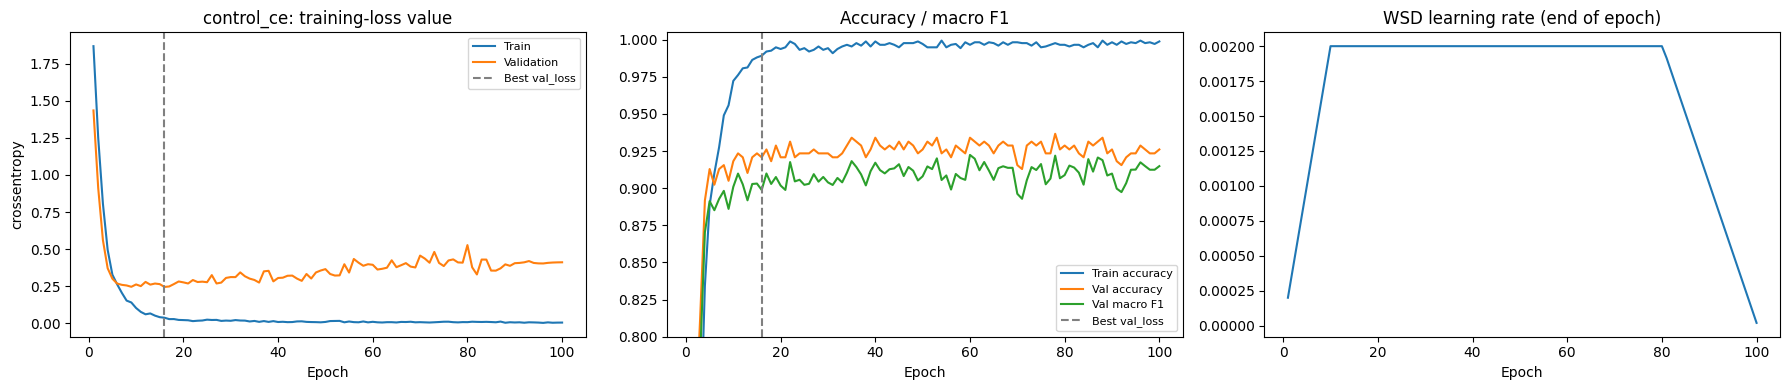

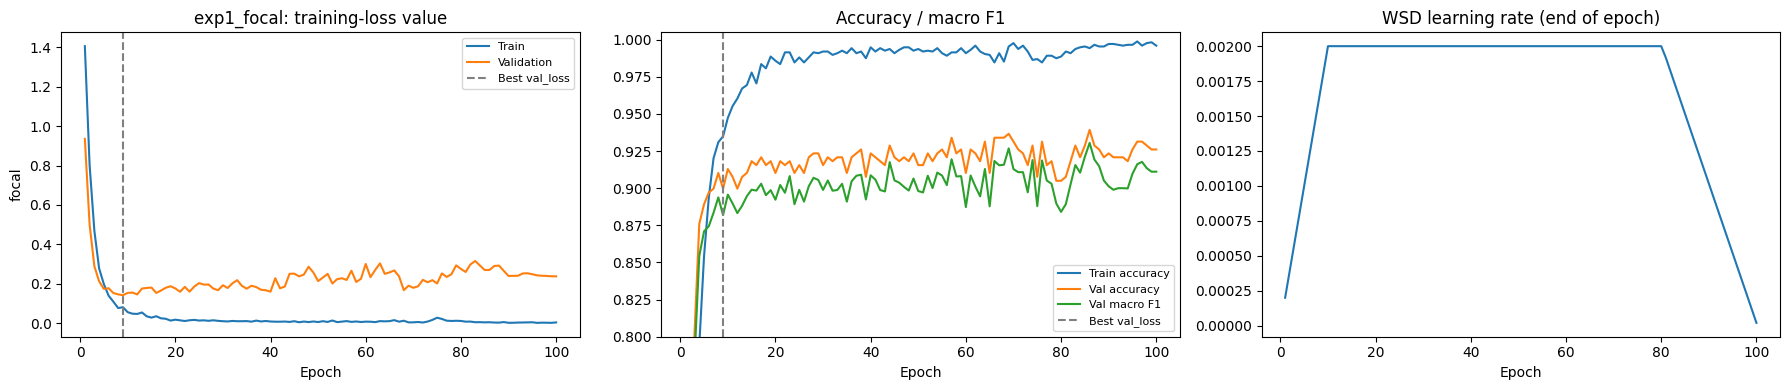

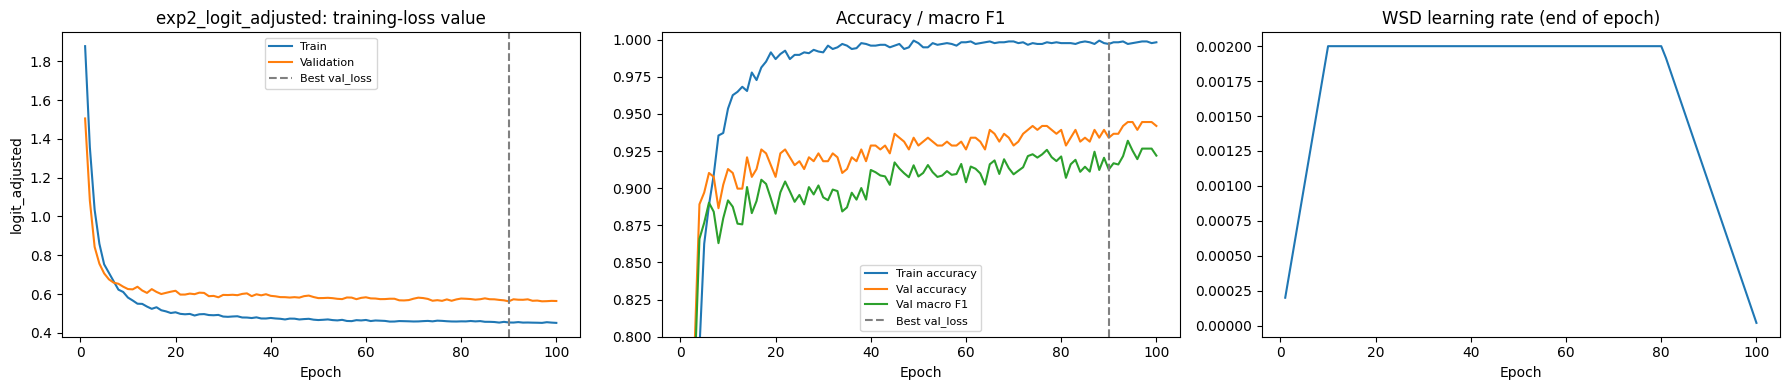

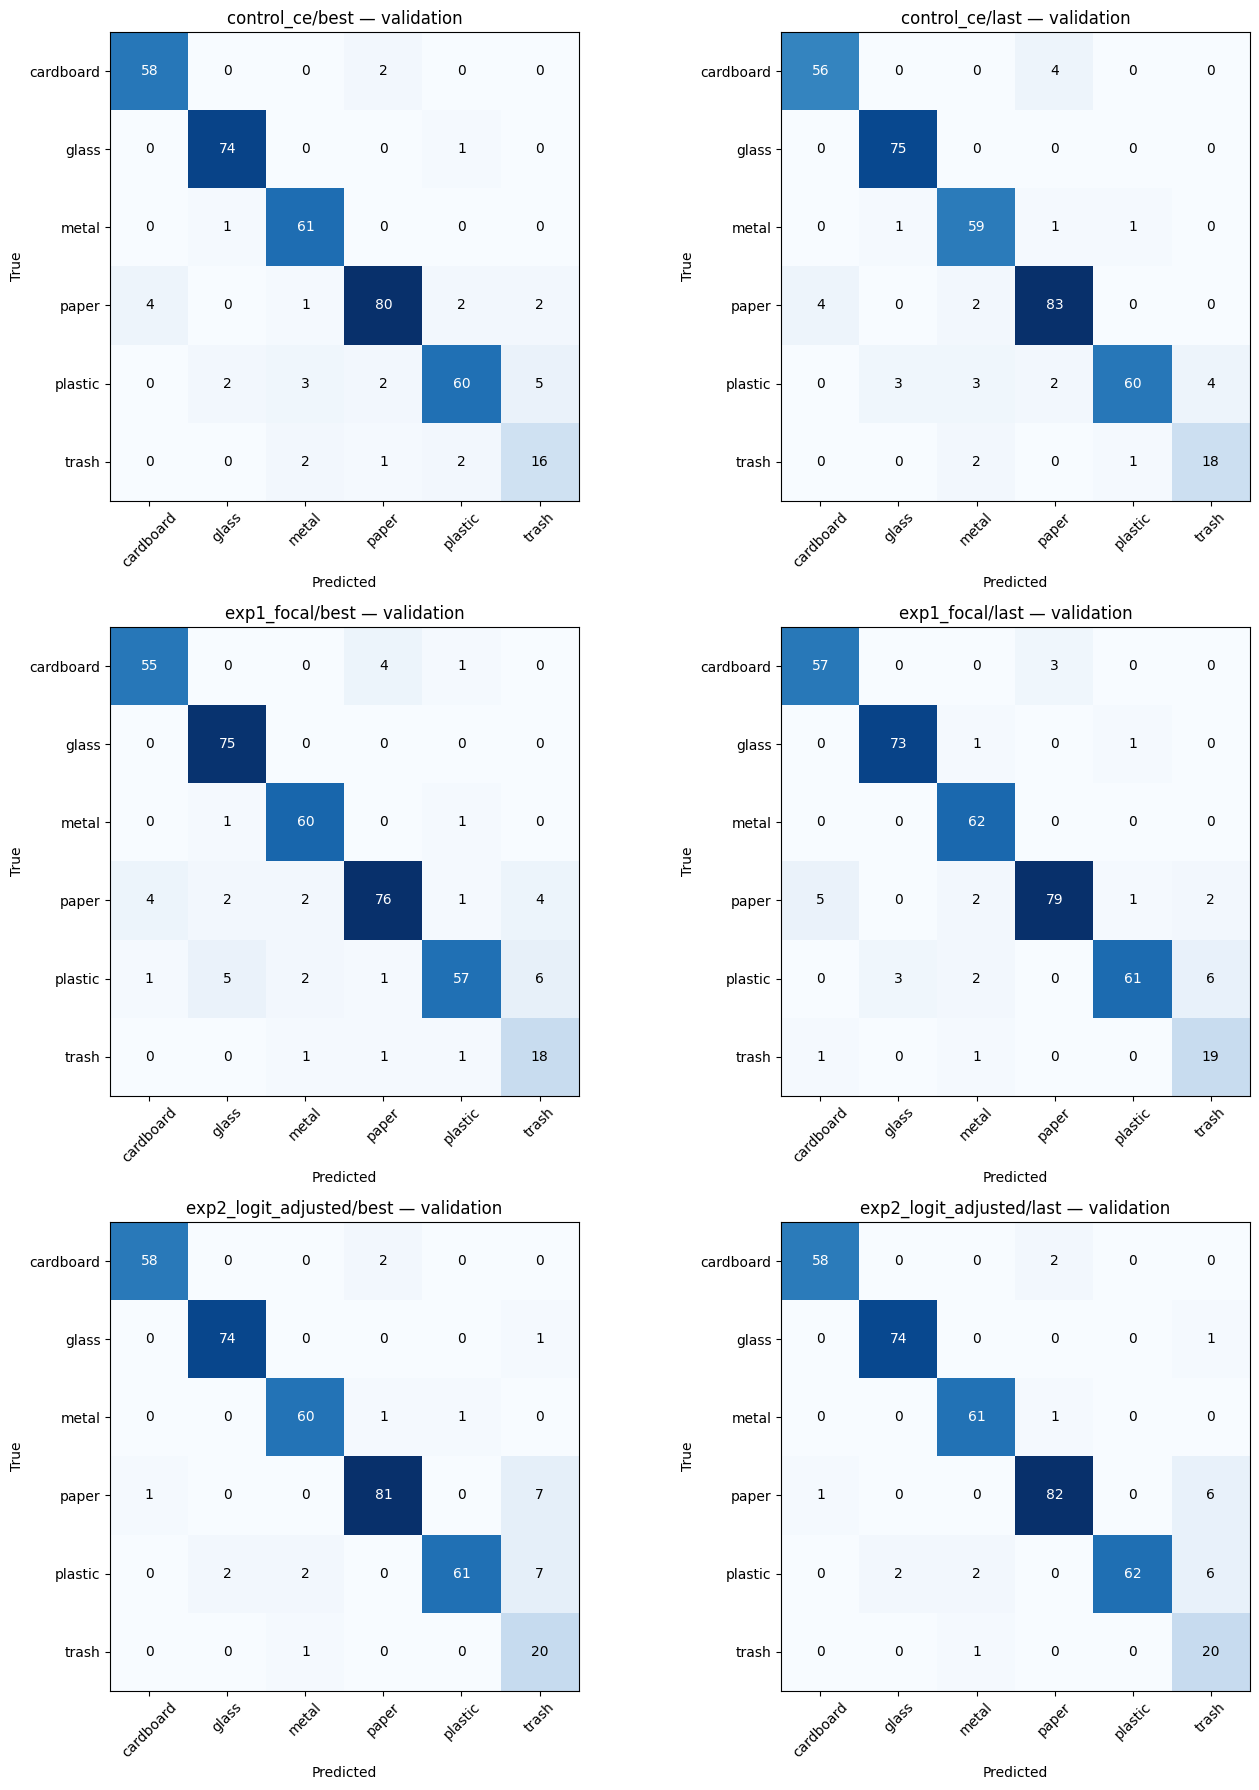

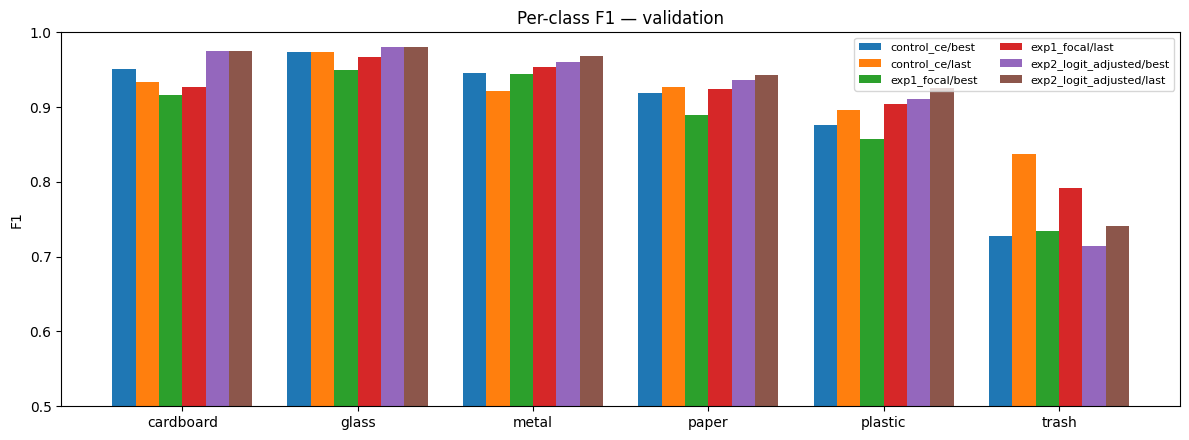

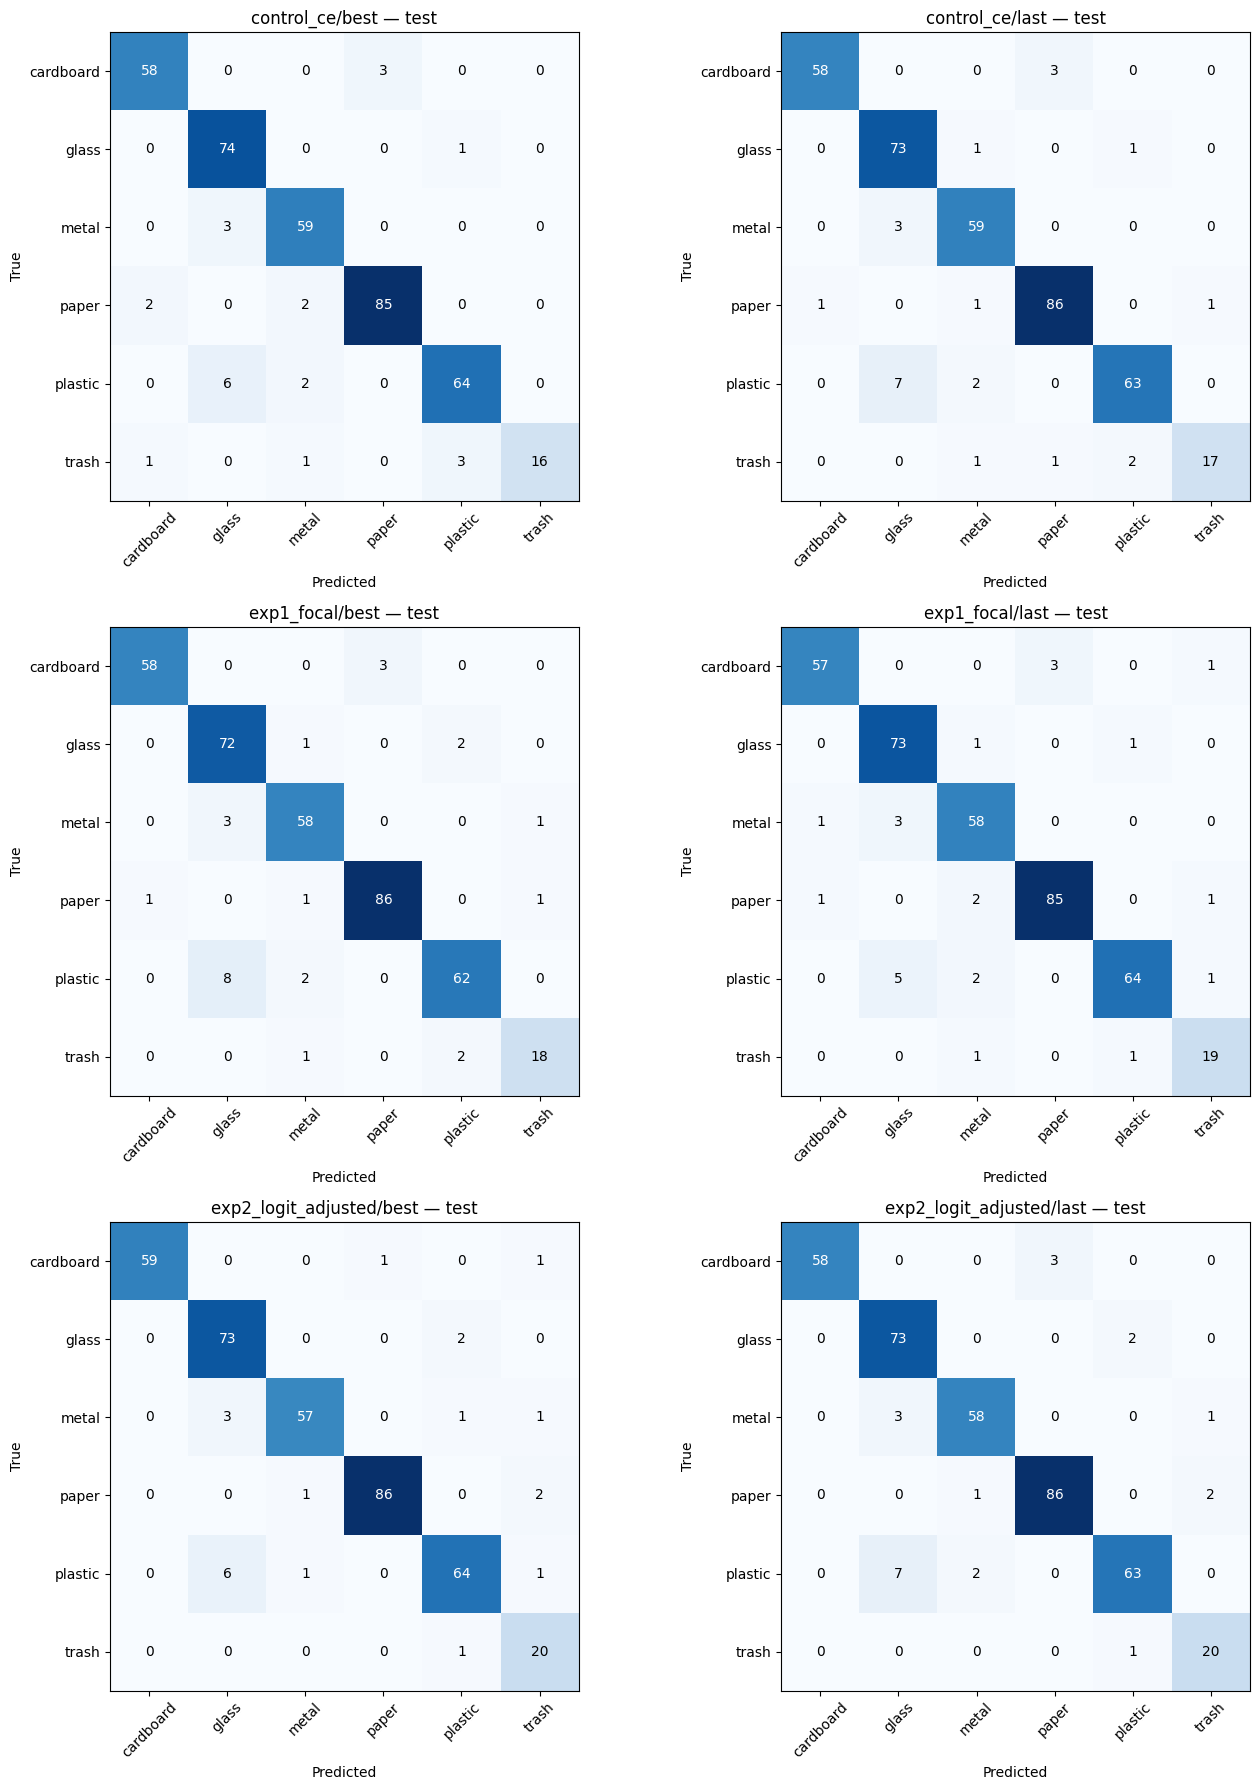

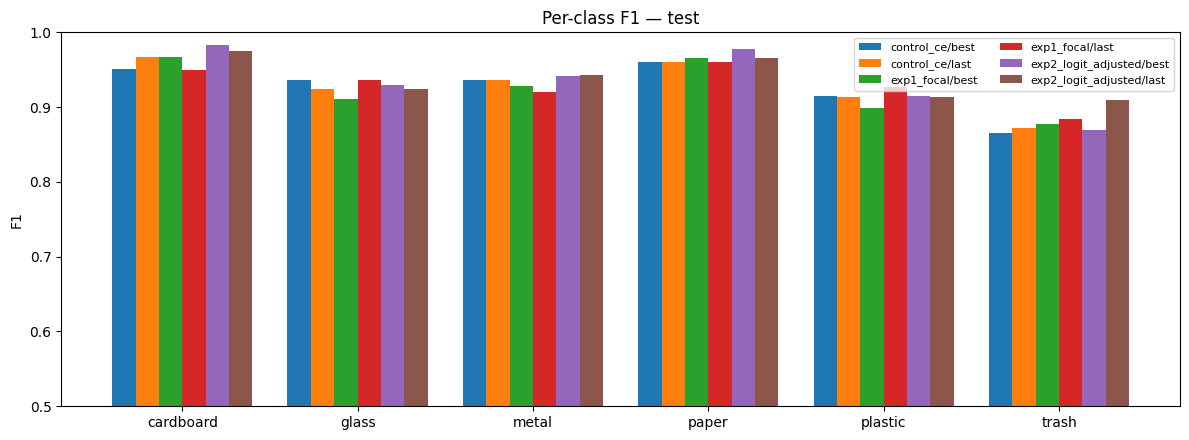

Saved artifacts: ['comparison.csv', 'confusion_matrices_test.png', 'confusion_matrices_validation.png', 'control_ce_best.keras', 'control_ce_epochs.csv', 'control_ce_history.json', 'control_ce_last.keras', 'control_ce_learning_curves.png', 'exp1_focal_best.keras', 'exp1_focal_epochs.csv', 'exp1_focal_history.json', 'exp1_focal_last.keras', 'exp1_focal_learning_curves.png', 'exp2_logit_adjusted_best.keras', 'exp2_logit_adjusted_epochs.csv', 'exp2_logit_adjusted_history.json', 'exp2_logit_adjusted_last.keras', 'exp2_logit_adjusted_learning_curves.png', 'feature_extraction.json', 'metrics.json', 'notebook_runtime.json', 'per_class_f1_test.png', 'per_class_f1_validation.png', 'per_class_test.csv', 'split_manifest.csv']
Notebook execution time: 9.11 minutes (546.4 seconds).


In [13]:
plot_training_curves(histories, OUTPUT_DIR)
for split_name in ('validation', 'test'):
    plot_confusion_grid(results, class_names, split_name, OUTPUT_DIR)
    plot_per_class_f1(comparison, class_names, split_name, OUTPUT_DIR)

elapsed_seconds = time.perf_counter() - notebook_started
(OUTPUT_DIR / 'notebook_runtime.json').write_text(json.dumps(
    {'execution_seconds': elapsed_seconds, 'execution_minutes': elapsed_seconds / 60.,
     'queue_time_included': False}, indent=2))
print('Saved artifacts:', sorted(path.name for path in OUTPUT_DIR.iterdir()))
print(f'Notebook execution time: {elapsed_seconds / 60.:.2f} minutes ({elapsed_seconds:.1f} seconds).')


## 10. Experiment 3: conservative training-image augmentation (Jesse)

**Research question:** Does mild image augmentation improve validation macro F1 / minority-class recall relative to the **same cross-entropy control**?

One variable changes: the training images passed through the same **frozen DINOv3 ConvNeXt-Tiny spatial backbone**. Architecture, head, 2×2 spatial representation, training labels/count, optimizer, learning-rate schedule, split, batch, and training budget remain the same.

- **Train only:** reproducible horizontal mirroring (50% probability) and rotation within ±10 degrees, preserving the 384×512 native dimensions. No crop or vertical flip: those transformations can discard an object or create unrealistic orientations.
- **Validation/test:** original, unchanged cached spatial features from the earlier notebook cells. Never augment evaluation images.
- **One augmented view per training row:** preserves the train count and the same steps/epoch as the control. This is *offline deterministic augmentation*, not fresh random augmentation each epoch.
- **Backbone extraction must rerun for the changed training pixels.** Applying image transforms to the cached 3,072-dimensional feature vectors would not constitute image augmentation.
- **Model selection:** compare validation metrics to `control_ce`, including `best` and `last`. Test metrics are reported once for the chosen checkpoint, not used to pick hyperparameters.

**Note:** The original notebook already displays test scores for multiple models; report that historical exploration as a limitation, and avoid further tuning based on test data.

In [14]:
from PIL import Image as PILImage, ImageOps

AUG_SEED = SEED + 400  # fixed, different RNG from the splitting seed
AUG_MAX_DEGREES = 10.0
AUG_FLIP_PROBABILITY = 0.5
AUG_NAME = 'exp3_augmentation'

def augmented_train_pixel_dataset(train_split, batch_size, seed=AUG_SEED):
    """Generate exactly one deterministic augmented 384x512 RGB view per train row.

    Same normalization as the baseline, and all transformations occur in PIL
    before passing pixels to the frozen backbone. Reproducibility is guaranteed
    for a fixed training order, seed, and PIL version.
    """
    rng = np.random.default_rng(seed)
    first_size = train_split[0]['image'].size
    width, height = first_size

    def make_pixels():
        for row in train_split:
            im = row['image'].convert('RGB')
            assert im.size == (width, height), f'Unexpected size: {im.size}'
            if rng.random() < AUG_FLIP_PROBABILITY:
                im = ImageOps.mirror(im)
            angle = float(rng.uniform(-AUG_MAX_DEGREES, AUG_MAX_DEGREES))
            im = im.rotate(angle, resample=PILImage.Resampling.BICUBIC,
                           expand=False, fillcolor=(255, 255, 255))
            yield preprocess_image(im)[0].numpy()

    ds = tf.data.Dataset.from_generator(
        make_pixels,
        output_signature=tf.TensorSpec(shape=(height, width, 3), dtype=tf.float32),
    )
    return ds.batch(batch_size).with_options(_single_worker_options()).prefetch(2)

assert len(splits['train']) == len(feature_cache['train'][1])
augmented_started = time.perf_counter()
aug_dataset = augmented_train_pixel_dataset(
    splits['train'], PER_REPLICA_EXTRACTION_BATCH * strategy.num_replicas_in_sync)
aug_outputs = backbone.predict(aug_dataset, verbose=0)
aug_maps = np.asarray(aug_outputs['feature_map'], dtype=np.float32)
assert aug_maps.shape[0] == len(splits['train']), aug_maps.shape
aug_vectors = spatial_grid_vectors(aug_maps)
del aug_outputs, aug_maps, aug_dataset
gc.collect()

assert aug_vectors.shape == feature_cache['train'][0].shape
assert np.isfinite(aug_vectors).all()
augmentation_extraction_seconds = time.perf_counter() - augmented_started
augmented_feature_cache = dict(feature_cache)
augmented_feature_cache['train'] = (aug_vectors, feature_cache['train'][1])
print('Augmented train features:', aug_vectors.shape)
print('Original train features:', feature_cache['train'][0].shape)
print(f'Augmented train-only extraction: {augmentation_extraction_seconds:.1f} seconds')


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Augmented train features: (1768, 3072)
Original train features: (1768, 3072)
Augmented train-only extraction: 87.0 seconds


In [15]:
aug_spec = {'name': AUG_NAME, 'loss': 'crossentropy'}
aug_started = time.perf_counter()
aug_best, aug_last, aug_meta = train_head_two_gpu(
    aug_spec, augmented_feature_cache, class_names, strategy, OUTPUT_DIR,
    batch_size=HEAD_BATCH_SIZE, epochs=HEAD_EPOCHS,
    peak_lr=PEAK_LEARNING_RATE, seed=SEED)
aug_meta['train_seconds'] = time.perf_counter() - aug_started
trained[AUG_NAME] = {'best': aug_best, 'last': aug_last}
histories[AUG_NAME] = aug_meta
print('Augmented run metadata:', {k:v for k,v in aug_meta.items() if k != 'history'})


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/100
INFO:tensorflow:batch_all_reduce: 6 all-reduces with algorithm = hierarchical_copy, num_packs = 1
7/7 - 3s - 361ms/step - accuracy: 0.2240 - f1_macro: 0.1984 - loss: 1.8793 - val_accuracy: 0.4697 - val_f1_macro: 0.4211 - val_loss: 1.4753
Epoch 2/100
7/7 - 1s - 115ms/step - accuracy: 0.5243 - f1_macro: 0.4747 - loss: 1.2840 - val_accuracy: 0.6728 - val_f1_macro: 0.6113 - val_loss: 0.9645
Epoch 3/100
7/7 - 1s - 114ms/step - accuracy: 0.7274 - f1_macro: 0.6647 - loss: 0.8235 - val_accuracy: 0.8127 - val_f1_macro: 0.7805 - val_loss: 0.5736
Epoch 4/100
7/7 - 1s - 115ms/step - accuracy: 0.8117 - f1_macro: 0.7836 - loss: 0.5199 - val_accuracy: 0.8602 - val_f1_macro: 0.8382 - val_loss: 0.4089
Epoch 5/100
7/7 - 1s - 115ms/step - accuracy: 0.8699 - f1_macro: 0.8454 - loss: 0.3642 - val_accuracy: 0.8839 - val_f1_macro: 0.8599 - val_loss: 0.3417
Epoch 6/100
7/7 - 1s - 114ms/step - accuracy: 0.9005 - f1_macro: 0.8813 - loss: 0.2862 - val_accuracy: 0.8997 - val_f1_macro: 0.8754 - val_los

In [16]:
# Evaluate validation first; compare only against the identical non-augmented CE control.
aug_val_reports = {}
for checkpoint, head in trained[AUG_NAME].items():
    y_val = feature_cache['validation'][1]
    val_probs = predict_probabilities(head, feature_cache['validation'][0])
    report = evaluate_probabilities(y_val, val_probs, class_names)
    aug_val_reports[checkpoint] = report

aug_rows = []
for model_name in ('control_ce', AUG_NAME):
    for checkpoint, head in trained[model_name].items():
        if model_name == AUG_NAME:
            report = aug_val_reports[checkpoint]
        else:
            report = results[f'{model_name}/{checkpoint}']['validation']
        aug_rows.append({'model':f'{model_name}/{checkpoint}',
                         **summarize_report(report, class_names)})
aug_val_table = pd.DataFrame(aug_rows).sort_values('f1_macro', ascending=False)
display(aug_val_table[['model','accuracy','f1_macro','balanced_accuracy',
                       'worst_class','worst_class_f1','f1_trash','f1_plastic']].round(4))
aug_val_table.to_csv(OUTPUT_DIR / 'augmentation_validation_comparison.csv', index=False)

# Choose between the augmented checkpoints using validation macro F1.
# The CE control remains a separately reported benchmark; do not use test data.
selected_aug_checkpoint = max(aug_val_reports, key=lambda key: aug_val_reports[key]['f1_macro'])
selected_aug_head = trained[AUG_NAME][selected_aug_checkpoint]
print('Selected augmented checkpoint based on validation macro F1:', selected_aug_checkpoint)


,model,accuracy,f1_macro,balanced_accuracy,worst_class,worst_class_f1,f1_trash,f1_plastic
1,control_ce/last,0.9261,0.9149,0.9180,trash,0.8372,0.8372,0.8955
2,exp3_augmentation/best,0.9235,0.8997,0.9106,trash,0.7083,0.7083,0.8741
0,control_ce/best,0.9208,0.8988,0.9052,trash,0.7273,0.7273,0.8759
3,exp3_augmentation/last,0.9182,0.8837,0.8844,trash,0.6341,0.6341,0.8857


Selected augmented checkpoint based on validation macro F1: best


FINAL selected augmentation test evaluation (not used for model selection)


,model,accuracy,f1_macro,balanced_accuracy,worst_class,worst_class_f1,f1_trash,f1_plastic
0,exp3_augmentation/best,0.9316,0.9208,0.9149,trash,0.85,0.85,0.9143


,class,support,precision,recall,f1,roc_auc,pr_auc
0,cardboard,61,1.0000,0.9016,0.9483,0.9976,0.9909
1,glass,75,0.9000,0.9600,0.9290,0.9935,0.9646
2,metal,62,0.8939,0.9516,0.9219,0.9878,0.9732
3,paper,89,0.9457,0.9775,0.9613,0.9969,0.9916
4,plastic,72,0.9412,0.8889,0.9143,0.9916,0.9739
5,trash,21,0.8947,0.8095,0.8500,0.9953,0.9473


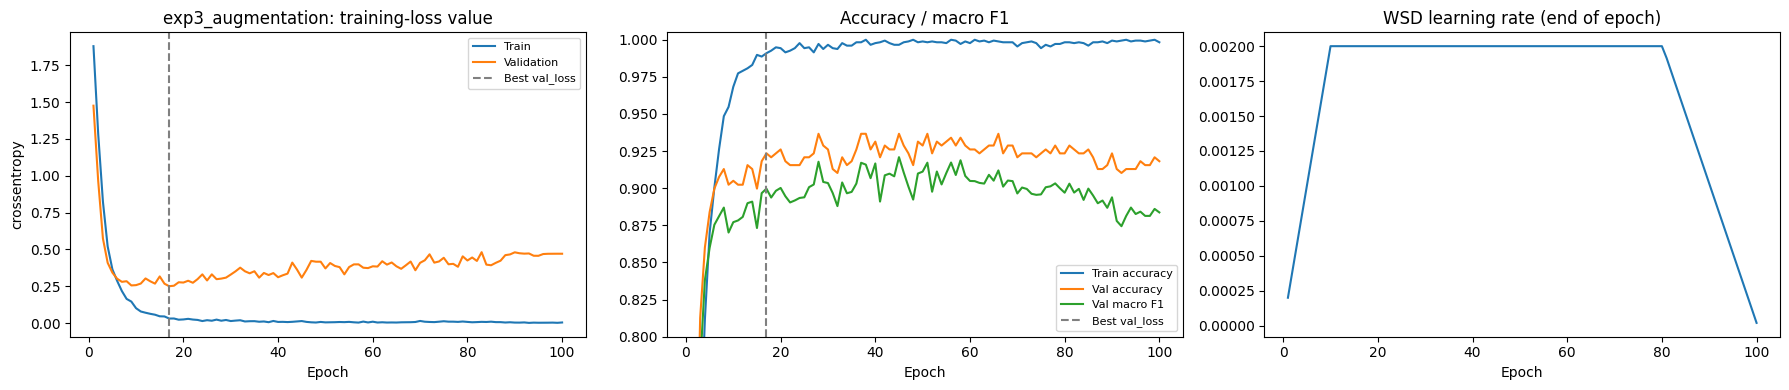

Saved augmented result files in /kaggle/working/outputs


In [17]:
# Only after selecting the augmented checkpoint by validation metrics, evaluate test once.
test_x, test_y = feature_cache['test']
aug_test_probabilities = predict_probabilities(selected_aug_head, test_x)
aug_test_report = evaluate_probabilities(test_y, aug_test_probabilities, class_names)
print('FINAL selected augmentation test evaluation (not used for model selection)')
display(pd.DataFrame([{'model': f'{AUG_NAME}/{selected_aug_checkpoint}',
                       **summarize_report(aug_test_report, class_names)}])
        [['model','accuracy','f1_macro','balanced_accuracy',
          'worst_class','worst_class_f1','f1_trash','f1_plastic']].round(4))
display(pd.DataFrame(aug_test_report['per_class']).round(4))
(OUTPUT_DIR / 'augmentation_final_test_metrics.json').write_text(
    json.dumps(aug_test_report, indent=2))
(OUTPUT_DIR / 'augmentation_protocol.json').write_text(json.dumps({
    'experiment':'train-only offline augmentation',
    'seed':AUG_SEED, 'flip_probability':AUG_FLIP_PROBABILITY,
    'rotation_degrees':[-AUG_MAX_DEGREES,AUG_MAX_DEGREES],
    'training_examples':len(splits['train']),
    'validation_test_original_unchanged':True,
    'augmented_feature_extraction_seconds':augmentation_extraction_seconds,
    'head_training_seconds':aug_meta['train_seconds'],
    'selected_checkpoint_by_validation_f1':selected_aug_checkpoint,
},indent=2))
plot_training_curves({AUG_NAME: aug_meta}, OUTPUT_DIR)
print('Saved augmented result files in', OUTPUT_DIR.resolve())


### Interpretation checklist (complete after running)

1. Report validation macro F1, trash recall/F1, and plastic recall/F1 versus the **cross-entropy control**; avoid claiming an improvement from a small difference without repeated-seed evidence.
2. State which checkpoint was selected and whether the change helped or hurt, including trade-offs for other classes.
3. Discuss likely overfitting: original heads had nearly perfect training accuracy despite lower validation metrics.
4. Be explicit that TrashNet has studio-style backgrounds and that augmentation does **not** demonstrate performance on cluttered conveyor belts.
5. Discuss inference time and extra training extraction time as separate costs. After training, deployment uses the **same frozen backbone** and **same classifier architecture** as control, so augmentation itself adds no inference computation.
6. The professor's *one major variable at a time* requirement is satisfied for **control vs augmentation**; the existing logit-adjusted experiment changes other training settings and should be described as a bundled configuration rather than isolated causal effect.
